# Граф переводов

**Задача.** Банк получает поручение: клиент переводит деньги на какой-то счёт. Нужно до исполнения оценить, не принадлежит ли счёт-получатель «дропу» – подставному лицу, через которое мошенники выводят деньги жертв. В F3 (MITRE Fight Fraud Framework) это техника F1049 Use Money Mule.

[https://ctid.mitre.org/fightfraud#/technique/F1049]

Можно смотреть только на сам счёт: сколько переводов пришло, на какие суммы. Но дропа специально делают похожим на обычного человека. Необходимо анализировать его окружение: деньги приходят от людей, которые раньше друг с другом не связаны, и быстро уходят на счета, которые тоже ведут себя странно. Идея графовой нейросети:исследовать не только сам счёт, но и его соседей.

**Разделы**

| Раздел | Описание |
|---|---|
| 1. Подготовка | библиотеки, общие настройки, загрузка датасета |
| 2. Датасет | выбираем столбцы и качество данных, строим граф счетов, считаем признаки, делим счета на выборки |
| 3. Логистическая регрессия | используем признаки самого счёта |
| 4. Градиентный бустинг | признаки счёта + средние признаки его соседей по графу |
| 5. GraphSAGE | графовая нейросеть |
| 6. Сравнение | все модели на одних и тех же тестовых счетах |

---
## Подготовка

### Импорт нужных библиотек

In [1]:
import time, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY = "#2f5d8a", "#d9822b", "#3a8a5c", "#b5473a", "#8a8f98"

In [2]:
#SEED – зерно случайности. От него зависит, какие счета попадут в обучение, проверку и тест,
#и с каких случайных весов начнёт нейросеть. При одном и том же SEED результат повторяется.
SEED = 42  # @param {type:"integer"}

np.random.seed(SEED)
torch.manual_seed(SEED)
print("SEED =", SEED)

SEED = 42


### Загрузка датасета

Датасет IBM AMLworld HI-Small - это синтетический набор транзакций, сгенерированных симулятором AMLworld для обучения и оценки моделей обнаружения отмывания денег. Его представили в работе «Realistic Synthetic Financial Transactions for Anti-Money Laundering Models» на конференции NeurIPS в 2023 году.

[https://arxiv.org/abs/2306.16424]

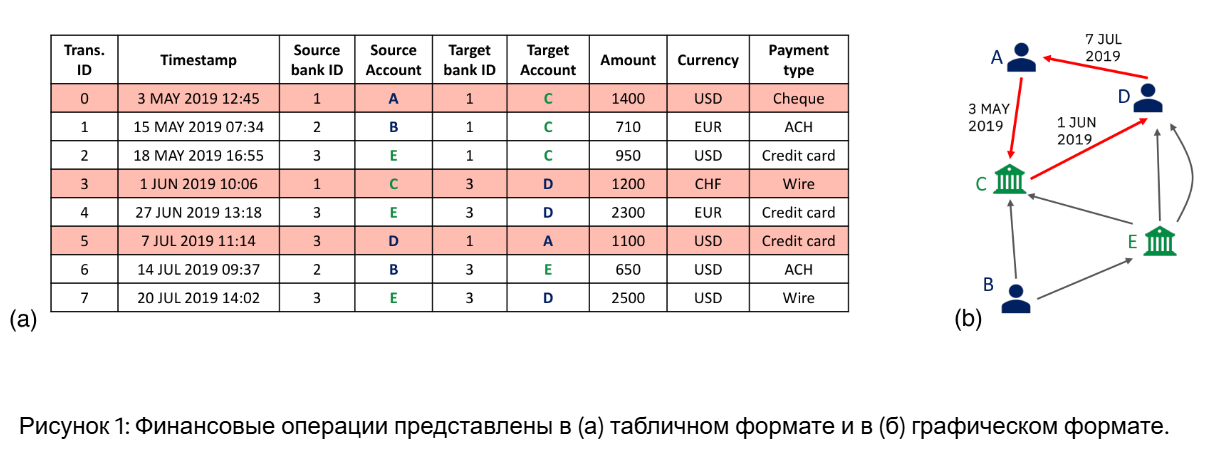

Финансовые преступления – это противоправные действия, совершаемые с целью получения финансовой выгоды. Финансовые преступления часто связаны с подозрительной активностью на счетах. Например, на графиках финансовых транзакций цикл представляет собой последовательность транзакций, в которых деньги, первоначально отправленные с одного банковского счета, возвращаются на тот же счет; наличие таких циклов является сильным индикатором отмывания денег. Рисунок  1b наглядно демонстрирует циклы отмывания денег, которые состоят из выделенных транзакций с рисунка  1a . Аналогичным образом, в сетях криптовалютных транзакций преступники используют сложные схемы смешивания и перемешивания , чтобы скрыть следы своей деятельности. Эффективное выявление подобных подозрительных моделей взаимодействия между владельцами учетных записей может обеспечить своевременное и экономически выгодное обнаружение преступной деятельности и ее исполнителей.

**Шаблоны AML**

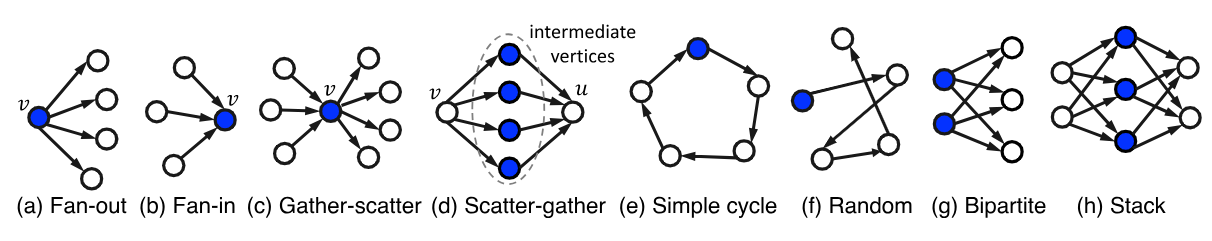

In [3]:
URL = "https://huggingface.co/datasets/bbfizp/AMLSim-HI-Small/resolve/main/HI-Small_Trans.csv"
CSV_PATH = "HI-Small_Trans.csv"

urllib.request.urlretrieve(URL, CSV_PATH)
print(f"{CSV_PATH}: {os.path.getsize(CSV_PATH) / 2**20:.0f} МБ")

HI-Small_Trans.csv: 454 МБ


---
## Датасет

Настоящие банковские переводы не опубликованы: это банковская тайна, большую часть схем никто не раскрыл. Поэтому для исследований используют синтетические данные. IBM AMLworld (Altman и др., NeurIPS 2023) – генератор, который моделирует банки, компании и переводы частных лиц: они получают зарплату, платят за покупки и услуги, а часть участников отмывает деньги по известным схемам (веер, цикл, разброс-сбор и т. д.).

[https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml]

### Наполнение файла

Каждой строке соответствует 1 перевод. Столбцов 11:

| Столбец | Описание |
|---|---|
| `Timestamp` | дата и время перевода (с точностью до минуты) |
| `From Bank` | код банка отправителя |
| `Account` | номер счёта отправителя |
| `To Bank` | код банка получателя |
| `Account.1` | номер счёта получателя (в файле второй столбец тоже называется `Account`, pandas переименовывает его) |
| `Amount Received` | сколько пришло получателю |
| `Receiving Currency` | валюта поступления |
| `Amount Paid` | сколько списали у отправителя |
| `Payment Currency` | валюта списания (не используется) |
| `Payment Format` | способ: ACH, Wire, Cheque, Credit Card, Cash, Bitcoin, Reinvestment |
| `Is Laundering` | **1 – перевод часть схемы отмывания**, 0 – обычный |

`Is Laundering` – целевая метрика, которую модели учатся угадывать.

In [4]:
df = pd.read_csv(CSV_PATH, dtype={"From Bank": str, "Account": str, "To Bank": str, "Account.1": str})
df.head(8)

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0
5,2022/09/01 00:03,001,8000F5AD0,001,8000F5AD0,6162.44,US Dollar,6162.44,US Dollar,Reinvestment,0
6,2022/09/01 00:08,001,8000EBAC0,001,8000EBAC0,14.26,US Dollar,14.26,US Dollar,Reinvestment,0
7,2022/09/01 00:16,001,8000EC1E0,001,8000EC1E0,11.86,US Dollar,11.86,US Dollar,Reinvestment,0


### 1.1 Типы столбцов и объём в памяти

In [5]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5078345 entries, 0 to 5078344
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Timestamp           object 
 1   From Bank           object 
 2   Account             object 
 3   To Bank             object 
 4   Account.1           object 
 5   Amount Received     float64
 6   Receiving Currency  object 
 7   Amount Paid         float64
 8   Payment Currency    object 
 9   Payment Format      object 
 10  Is Laundering       int64  
dtypes: float64(2), int64(1), object(8)
memory usage: 2.3 GB


### 1.2. Проверка качества

#### Пропуски, дубликаты, переводы самому себе

In [6]:
ts = pd.to_datetime(df["Timestamp"], format="%Y/%m/%d %H:%M")
src_key = df["From Bank"] + ":" + df["Account"] # счёт = банк + номер
dst_key = df["To Bank"] + ":" + df["Account.1"]
ill = df["Is Laundering"] == 1
self_tx = src_key == dst_key

checks = pd.Series({
    "строк": len(df),
    "пустых ячеек (во всех столбцах)": int(df.isna().sum().sum()),
    "полностью одинаковых строк": int(df.duplicated().sum()),
    "переводов самому себе": int(self_tx.sum()),
    "  из них «отмывание»": int((self_tx & ill).sum()),
    "переводов с обменом валюты": int((df["Receiving Currency"] != df["Payment Currency"]).sum()),
    "переводов «отмывание»": int(ill.sum()),
    "доля «отмывания», %": round(ill.mean() * 100, 3),
    "разных банков": pd.concat([df["From Bank"], df["To Bank"]]).nunique(),
    "разных счетов": pd.concat([src_key, dst_key]).nunique(),
}, dtype=object).to_frame("значение")
print("Период:", ts.min(), "-", ts.max())
checks

Период: 2022-09-01 00:00:00 - 2022-09-18 16:18:00


,значение
строк,5078345
пустых ячеек (во всех столбцах),0
полностью одинаковых строк,9
переводов самому себе,591212
из них «отмывание»,11
переводов с обменом валюты,72170
переводов «отмывание»,5177
"доля «отмывания», %",0.102
разных банков,30528
разных счетов,515088


**Основные выводы:**

- **Пропусков нет**
- **Одинаковых строк 9** из 5 млн. Это могут быть и настоящие повторные платежи (та же сумма в ту же минуту), поэтому их не удаляем.
- **Переводы самому себе** (около 590 тыс.) не связывают два разных счёта, поэтому в граф их не берём.
- **Суммы в 15 валютах**, включая биткоин. Чтобы их можно было сравнивать, переводим всё в доллары по примерным курсам.
- **Классы сильно несбалансированы**: «отмывание» – около 0,1 % переводов.

#### Переводы по дням

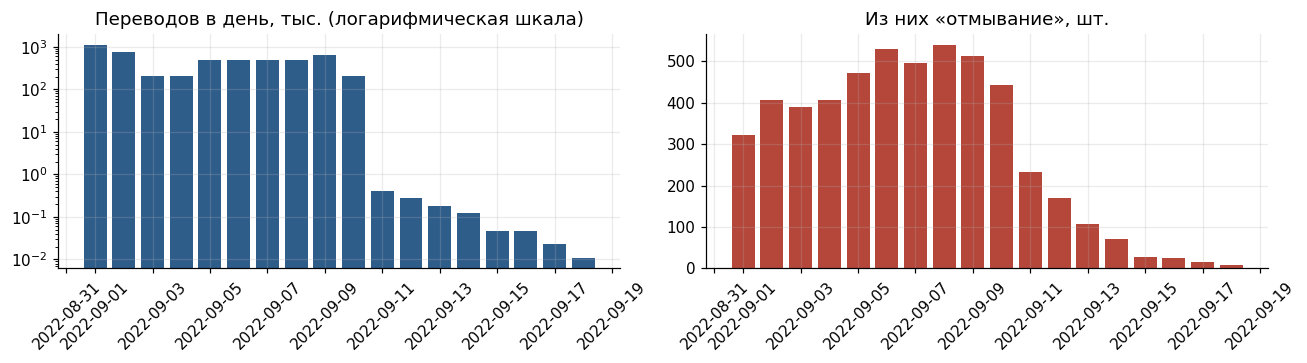

In [7]:
day = ts.dt.normalize()
by_day = pd.DataFrame({"всего": day.value_counts().sort_index(), "отмывание": day[ill].value_counts().sort_index()}).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(by_day.index, by_day["всего"] / 1000, color=BLUE)
ax[0].set_yscale("log"); ax[0].set_title("Переводов в день, тыс. (логарифмическая шкала)")
ax[1].bar(by_day.index, by_day["отмывание"], color=RED)
ax[1].set_title("Из них «отмывание», шт.")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

С 11 сентября переводов почти нет (сотни в день), и больше половины из них помечены как «отмывание».

#### Способы оплаты

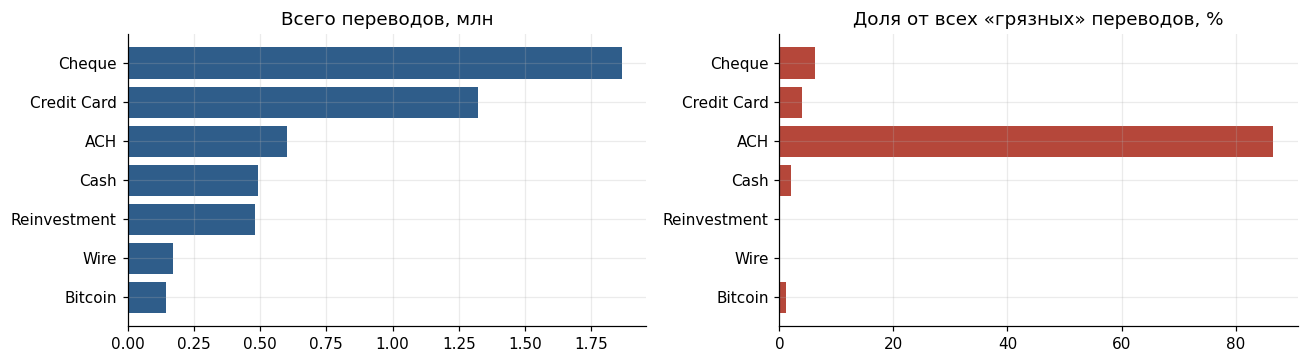

,переводов,отмывание,"доля отмывания, %","доля от всего отмывания, %"
Payment Format,,,,
Cheque,1864331,324,0.017,6.3
Credit Card,1323324,206,0.016,4.0
ACH,600797,4483,0.746,86.6
Cash,490891,108,0.022,2.1
Reinvestment,481056,0,0.000,0.0
Wire,171855,0,0.000,0.0
Bitcoin,146091,56,0.038,1.1


In [8]:
fm = pd.DataFrame({"переводов": df["Payment Format"].value_counts(), "отмывание": df.loc[ill, "Payment Format"].value_counts()}).fillna(0).astype(int)
fm["доля отмывания, %"] = (fm["отмывание"] / fm["переводов"] * 100).round(3)
fm["доля от всего отмывания, %"] = (fm["отмывание"] / fm["отмывание"].sum() * 100).round(1)
fm = fm.sort_values("переводов", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].barh(fm.index, fm["переводов"] / 1e6, color=BLUE); ax[0].invert_yaxis()
ax[0].set_title("Всего переводов, млн")
ax[1].barh(fm.index, fm["доля от всего отмывания, %"], color=RED); ax[1].invert_yaxis()
ax[1].set_title("Доля от всех «грязных» переводов, %")
plt.tight_layout(); plt.show()
fm

Чеки и кредитные карты – самые частые форматы, а большинство транзакций с меткой отмывания приходится на ACH. Вывод: формат платежа может быть полезным признаком для модели.

### 1.3. Строим граф счетов

Дальше работаем не с переводами, а со счетами:

- **вершина** графа – счёт (банк + номер);
- **ребро A → B** – со счёта A хотя бы раз переводили на счёт B.

Каждому счёту даём номер от 0 до N−1, чтобы дальше работать с массивами чисел, а не со строками.

#### Номера счетов и рёбра

In [9]:
USD_RATE = {  # примерные курсы к доллару (2022 г.)
    "US Dollar": 1.0, "Euro": 1.0, "UK Pound": 1.17, "Swiss Franc": 1.03, "Canadian Dollar": 0.75,
    "Australian Dollar": 0.68, "Yuan": 0.145, "Yen": 0.0071, "Rupee": 0.0125, "Ruble": 0.017,
    "Shekel": 0.29, "Mexican Peso": 0.05, "Brazil Real": 0.19, "Saudi Riyal": 0.27, "Bitcoin": 20000.0,
}
FORMATS = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]

total_rows = len(df)
codes, keys = pd.factorize(pd.concat([src_key, dst_key], ignore_index=True))
keys = np.asarray(keys, dtype=str)
N = len(keys)
src = codes[:total_rows].astype(np.int64) # номер счёта-отправителя для каждого перевода
dst = codes[total_rows:].astype(np.int64) # номер счёта-получателя

minutes = ((ts - ts.min()).dt.total_seconds() // 60).astype(np.int64).to_numpy()
usd = df["Amount Received"].to_numpy() * df["Receiving Currency"].map(USD_RATE).astype(float).to_numpy()
fmt = df["Payment Format"].map({f: i for i, f in enumerate(FORMATS)}).astype(int).to_numpy()
cur = df["Receiving Currency"].astype("category").cat.codes.to_numpy()
illicit = df["Is Laundering"].to_numpy().astype(bool)

# Убираем переводы самому себе
keep = src != dst
src, dst, minutes, usd, fmt, cur, illicit = (a[keep] for a in (src, dst, minutes, usd, fmt, cur, illicit))

edges = np.unique(np.stack([src, dst], 1), axis=0)   # уникальные пары A→B
print(f"Счетов (вершин): {N:,}\nПереводов между разными счетами: {len(src):,}\nРёбер (уникальных пар A→B): {len(edges):,}".replace(",", " "))

Счетов (вершин): 515 088
Переводов между разными счетами: 4 487 133
Рёбер (уникальных пар A→B): 647 939


### 1.4. Признаки счёта

Для каждого счёта считаем 17 чисел. По ним модели будут судить о счёте. Идея признаков в том, чтобы описать поведение «транзитного» счёта: на него приходит много денег от разных людей, и почти сразу всё уходит дальше.

| № | Признак | Как считается |
|---|---|---|
| 0 | входящих переводов | сколько переводов пришло на счёт |
| 1 | исходящих переводов | сколько ушло со счёта |
| 2 | сумма входящих, долл. | всё, что пришло, в долларах |
| 3 | сумма исходящих, долл. | всё, что ушло |
| 4 | разных отправителей | от скольких разных счетов приходили деньги |
| 5 | разных получателей | на сколько разных счетов отправлял |
| 6 | доля пересланного дальше | сумма исходящих / сумма входящих (не больше 5) |
| 7 | пересылка в течение суток | доля исходящих переводов, сделанных в первые 24 ч после первого поступления |
| 8 | дней активности | от первого до последнего перевода счёта |
| 9 | разных валют на входе | сколько валют приходило |
| 10–16 | доля входящих по способу | доля входящих переводов через ACH, Bitcoin, Cash, Cheque, Credit Card, Reinvestment, Wire |

#### Подсчёт 17 признаков

In [10]:
in_cnt  = np.bincount(dst, minlength=N) # 0
out_cnt = np.bincount(src, minlength=N) # 1
in_sum  = np.bincount(dst, weights=usd, minlength=N) # 2
out_sum = np.bincount(src, weights=usd, minlength=N) # 3
uniq_senders   = np.bincount(edges[:, 1], minlength=N) # 4
uniq_receivers = np.bincount(edges[:, 0], minlength=N) # 5
pass_ratio = np.where(in_sum > 0, np.minimum(out_sum / np.maximum(in_sum, 1e-9), 5.0), 0.0) # 6

# 7: время первого поступления -> какая доля исходящих сделана в течение суток после него
first_in = np.full(N, np.iinfo(np.int64).max)
np.minimum.at(first_in, dst, minutes)
after = minutes - first_in[src]
quick = (after >= 0) & (after <= 24 * 60)
quick_share = np.where(out_cnt > 0, np.bincount(src, weights=quick, minlength=N) / np.maximum(out_cnt, 1), 0.0)

# 8: дни активности
t_min = np.full(N, np.iinfo(np.int64).max); t_max = np.zeros(N, dtype=np.int64)
np.minimum.at(t_min, src, minutes); np.minimum.at(t_min, dst, minutes)
np.maximum.at(t_max, src, minutes); np.maximum.at(t_max, dst, minutes)
days = np.where(t_max >= t_min, (t_max - t_min) / (24 * 60), 0.0)

# 9: разных валют на входе
cur_pairs = np.unique(np.stack([dst, cur], 1), axis=0)
n_cur = np.bincount(cur_pairs[:, 0], minlength=N)

# 10–16: доли способов оплаты среди входящих
fmt_share = np.zeros((N, len(FORMATS)))
np.add.at(fmt_share, (dst, fmt), 1)
fmt_share = fmt_share / np.maximum(in_cnt, 1)[:, None]

FEATURE_NAMES = ["входящих переводов", "исходящих переводов", "сумма входящих, $", "сумма исходящих, $", "разных отправителей", "разных получателей", "доля пересланного дальше", "пересылка в течение суток", "дней активности", "разных валют на входе"] + ["доля входящих: " + f for f in FORMATS]

raw = np.column_stack([in_cnt, out_cnt, in_sum, out_sum, uniq_senders, uniq_receivers, pass_ratio, quick_share, days, n_cur, fmt_share]).astype(np.float32)
print("Матрица признаков:", raw.shape, "(счетов × признаков)")
pd.DataFrame(raw[:5], columns=FEATURE_NAMES, index=keys[:5]).round(2)

Матрица признаков: (515088, 17) (счетов × признаков)


,входящих переводов,исходящих переводов,"сумма входящих, $","сумма исходящих, $",разных отправителей,разных получателей,доля пересланного дальше,пересылка в течение суток,дней активности,разных валют на входе,доля входящих: ACH,доля входящих: Bitcoin,доля входящих: Cash,доля входящих: Cheque,доля входящих: Credit Card,доля входящих: Reinvestment,доля входящих: Wire
010:8000EBD30,13.0,1.0,924.989990,1.466600e+02,12.0,1.0,0.16,0.00,8.00,1.0,0.00,0.0,0.0,0.15,0.85,0.0,0.0
03208:8000F4580,0.0,3.0,0.000000,1.440670e+03,0.0,2.0,0.00,0.00,8.42,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0
03209:8000F4670,0.0,0.0,0.000000,0.000000e+00,0.0,0.0,0.00,0.00,0.00,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0
012:8000F5030,19.0,1.0,13055.700195,1.171450e+05,19.0,1.0,5.00,0.00,9.02,1.0,0.42,0.0,0.0,0.00,0.58,0.0,0.0
010:8000F5200,10.0,29.0,740.210022,1.502425e+06,8.0,4.0,5.00,0.14,9.96,1.0,0.00,0.0,0.0,0.00,1.00,0.0,0.0


### 1.5. Правильный ответ (метка)

Метка счёта = 1, если на него хотя бы раз пришёл перевод с `Is Laundering = 1`. Иначе 0. Оцениваем счета-получатели (у кого был хотя бы один входящий перевод).

#### Метки и баланс классов

Счетов-получателей: 284 394
Из них дропов (метка 1): 3 984 – 1.40 %


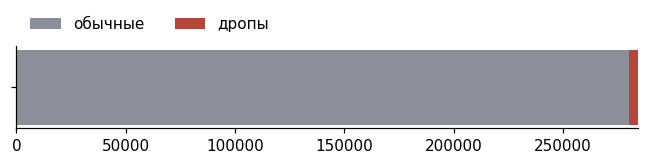

In [11]:
y = np.zeros(N, dtype=np.int64)
y[np.unique(dst[illicit])] = 1
recipients = in_cnt > 0

n_rec, n_drop = int(recipients.sum()), int(y[recipients].sum())
print(f"Счетов-получателей: {n_rec:,}\nИз них дропов (метка 1): {n_drop:,} – {n_drop / n_rec * 100:.2f} %".replace(",", " "))

fig, ax = plt.subplots(figsize=(6, 1.6))
ax.barh([""], [n_rec - n_drop], color=GREY, label="обычные")
ax.barh([""], [n_drop], left=[n_rec - n_drop], color=RED, label="дропы")
ax.set_xlim(0, n_rec); ax.legend(loc="lower left", ncol=2, frameon=False, bbox_to_anchor=(0, 1))
ax.grid(False); plt.tight_layout(); plt.show()

#### Чем дроп отличается от обычного счёта (медианы признаков)

In [12]:
cmp = pd.DataFrame({
    "обычный счёт": np.median(raw[recipients & (y == 0)], 0),
    "дроп": np.median(raw[recipients & (y == 1)], 0),
}, index=FEATURE_NAMES).round(3)
cmp

,обычный счёт,дроп
входящих переводов,16.000000,14.000000
исходящих переводов,1.000000,2.000000
"сумма входящих, $",26530.031250,26833.876953
"сумма исходящих, $",2217.763916,7831.850098
разных отправителей,2.000000,3.000000
разных получателей,1.000000,1.000000
доля пересланного дальше,0.042000,0.238000
пересылка в течение суток,0.000000,0.000000
дней активности,8.653000,8.672000
разных валют на входе,1.000000,1.000000


### 1.6. Масштабирование признаков

Признаки счетов измеряются в разных единицах и имеют разные численные масштабы. Например, у обычных счетов-получателей медианное число входящих переводов составляет 16, а медианная сумма поступлений около 26,5 тыс. долларов. Распределение сумм поступлений имеет длинную правую часть. Поэтому решено сделать два шага:

1. **Логарифм** log(1 + x) для счётчиков, сумм и дней (признаки 0, 1, 2, 3, 4, 5, 8), который сжимает огромные значения;
2. **Стандартизация**: Затем каждый столбец центрировали вычитанием среднего и масштабировали делением на стандартное отклонение с добавлением 10^-6 в знаменатель. Стандартизацию применили, чтобы привести входные признаки логистической регрессии и GraphSAGE к сопоставимому масштабу.

#### Логарифм + стандартизация

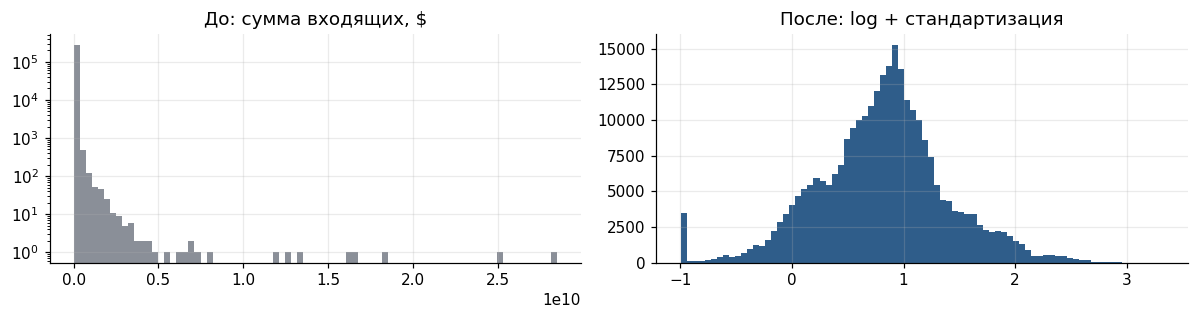

In [13]:
x = raw.copy()
LOG_COLS = (0, 1, 2, 3, 4, 5, 8)
for j in LOG_COLS:
    x[:, j] = np.log1p(x[:, j])
x = (x - x.mean(0)) / (x.std(0) + 1e-6)

j = 2
m = recipients
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(raw[m, j], bins=80, color=GREY); ax[0].set_title("До: сумма входящих, $"); ax[0].set_yscale("log")
ax[1].hist(x[m, j], bins=80, color=BLUE); ax[1].set_title("После: log + стандартизация")
plt.tight_layout(); plt.show()

### 1.7. Делим счета: обучение / проверка / тест

Счета-получатели случайно делятся на три группы, причём доля дропов в каждой одинаковая (стратификация):

- **обучение, 70 %** – на них модель учится;
- **проверка, 15 %** – по ним выбираем порог решения и лучшую эпоху нейросети;
- **тест, 15 %** – Счета, которые модель ещё не видела. На них считаем итоговые цифры.

In [14]:
def make_split(y, candidates, seed):
    rng = np.random.default_rng(seed)
    split = np.zeros(len(y), dtype=np.int8)
    for cls in (0, 1):
        idx = np.where(candidates & (y == cls))[0]
        rng.shuffle(idx)
        a, b = int(len(idx) * 0.70), int(len(idx) * 0.85)
        split[idx[:a]], split[idx[a:b]], split[idx[b:]] = 1, 2, 3
    return split

split = make_split(y, recipients, SEED)
tr, va, te = split == 1, split == 2, split == 3
pd.DataFrame({"счетов": [tr.sum(), va.sum(), te.sum()], "дропов": [y[tr].sum(), y[va].sum(), y[te].sum()]}, index=["обучение", "проверка", "тест"])

,счетов,дропов
обучение,199075,2788
проверка,42659,598
тест,42660,598


### 1.8. Параметры оценки модели

Модель выдаёт каждому счёту оценку риска. Чем выше, тем подозрительнее. Метрики:

- **PR-AUC** – площадь под кривой «точность – полнота». Если выстроить счета по убыванию оценки, PR-AUC показывает, насколько дропы собраны наверху списка. Идеально 1.
- **ROC-AUC** – вероятность, что случайный дроп получит оценку выше случайного обычного счёта.
- **Полнота при 1 % ложных тревог** – какую долю дропов поймаем, если готовы зря проверить 1 честный счёт из 100.
- **Точность в топ-100** – сколько настоящих дропов среди 100 самых подозрительных счетов теста.

#### Функции оценки

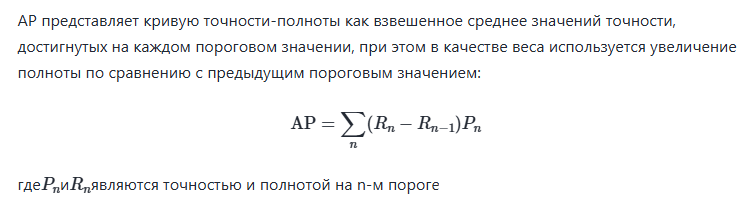

[https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html]

Характеристика рабочей кривой приемника (ROC), или просто ROC-кривая, – это графический график, иллюстрирующий эффективность системы бинарной классификации при изменении порога дискриминации. Она строится путем построения графика зависимости доли истинно положительных результатов от доли истинно положительных результатов (TPR = доля истинно положительных результатов) от доли ложноположительных результатов от доли ложноположительных результатов (FPR = доля ложноположительных результатов) при различных значениях порога. TPR также известна как чувствительность, а FPR – это единица минус специфичность или доля истинно отрицательных результатов».

[https://scikit-learn.org/stable/modules/model_evaluation.html#receiver-operating-characteristic-roc]

In [15]:
RESULTS = {}

def evaluate(y_true, s):
    neg = s[y_true == 0]
    top = np.argsort(-s)[:100]
    return {
        "PR-AUC": average_precision_score(y_true, s),
        "ROC-AUC": roc_auc_score(y_true, s),
        "полнота при 1% ложных": (s[y_true == 1] > np.quantile(neg, 0.99)).mean(),
        "точность топ-100": y_true[top].mean(),
    }

def decide(score):
    p, r, t = precision_recall_curve(y[va], score[va])
    f1 = (2 * p * r / np.maximum(p + r, 1e-9))[:-1]
    thr = t[int(np.argmax(f1))]
    pred, yt = score[te] >= thr, y[te] == 1
    return {"порог": thr, "поймано дропов": int((pred & yt).sum()), "пропущено дропов": int((~pred & yt).sum()), "ложных тревог": int((pred & ~yt).sum()), "обычных без тревоги": int((~pred & ~yt).sum())}

def report(name, score):
    m, d = evaluate(y[te], score[te]), decide(score)
    RESULTS[name] = {"score": score, **m, **d}
    print(pd.Series(m).round(3).to_string()); print()
    print("Решение на пороге (тестовые счета):")
    print(pd.Series(d, dtype=object).to_string())
    p, r, _ = precision_recall_curve(y[te], score[te])
    plt.figure(figsize=(5, 3.4))
    plt.plot(r, p, color=BLUE)
    plt.axhline(y[te].mean(), color=GREY, ls="--", lw=1, label="случайное угадывание")
    plt.xlabel("полнота (доля пойманных дропов)"); plt.ylabel("точность")
    plt.title(f"{name}: PR-AUC = {m['PR-AUC']:.3f}"); plt.legend(frameon=False)
    plt.tight_layout(); plt.show()

## Простое правило без мо

Прежде чем обучать модели, проверим самое простое правило без обучения: Чем больше разных отправителей, тем подозрительнее (признак 4). Любая модель должна быть заметно лучше этого.

PR-AUC                   0.033
ROC-AUC                  0.679
полнота при 1% ложных    0.059
точность топ-100         0.100

Решение на пороге (тестовые счета):
порог                    7.0
поймано дропов            52
пропущено дропов         546
ложных тревог            753
обычных без тревоги    41309


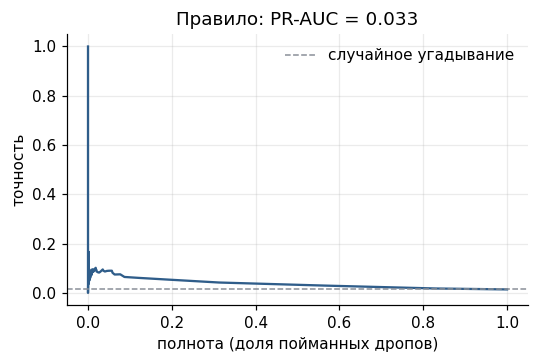

In [16]:
report("Правило", raw[:, 4].astype(float))

AP = 0,033 показывает, что при переборе порогов точность обнаружения дропов остаётся низкой по мере роста полноты. ROC-AUC = 0,679 означает, что правило ставит дропа выше обычного счёта примерно в 68% парных сравнений с учётом совпадающих оценок. При доле ложных тревог около 1% среди обычных счетов правило выявляет 5,9% дропов. Из 805 тревог 753 оказались ложными, поэтому точность при этом пороге составила 6,5%.

---
## Модель 1: Логистическая регрессия

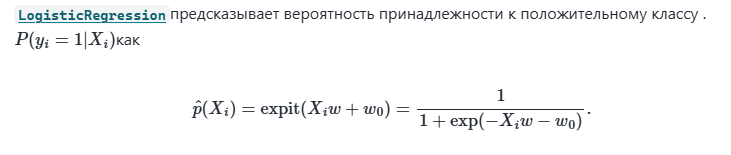

[https://scikit-learn.org/stable/modules/linear_model.html#binary-case]

В нашем случае модель складывает 17 признаков счёта с весами и превращает сумму в вероятность:

$$p = \sigma(w_0 + w_1 x_1 + \dots + w_{17} x_{17}), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

#### Параметры логистической регрессии

In [17]:
C = 1.0  # @param {type:"number"}
CLASS_WEIGHT = "balanced"  # @param ["balanced", "None"]
MAX_ITER = 500  # @param {type:"integer"}



*   Параметр C управляет регуляризацией. Чем меньше C, тем сильнее штраф за большие коэффициенты w.
*   class_weight='balanced' даёт больший вес каждому редкому дропу при расчёте потерь, так как в обучающей выборке очень мало дропов (196 287 обычных счетов и 2 788 дропов, примерно один дроп на 70 обычных счетов). При одинаковом весе каждого счёта обычные счета влияли бы на функцию потерь уже за счёт своей численности.




#### Обучение

In [18]:
t0 = time.time()
logreg = LogisticRegression(C=C, class_weight=None if CLASS_WEIGHT == "None" else CLASS_WEIGHT, max_iter=MAX_ITER)
logreg.fit(x[tr], y[tr])
print(f"Обучено за {time.time() - t0:.1f} с, шагов оптимизации: {logreg.n_iter_[0]}")
s_logreg = logreg.predict_proba(x)[:, 1]

Обучено за 2.6 с, шагов оптимизации: 33


#### Результат на тесте

PR-AUC                   0.054
ROC-AUC                  0.799
полнота при 1% ложных    0.059
точность топ-100         0.090

Решение на пороге (тестовые счета):
порог                  0.823608
поймано дропов              121
пропущено дропов            477
ложных тревог              1339
обычных без тревоги       40723


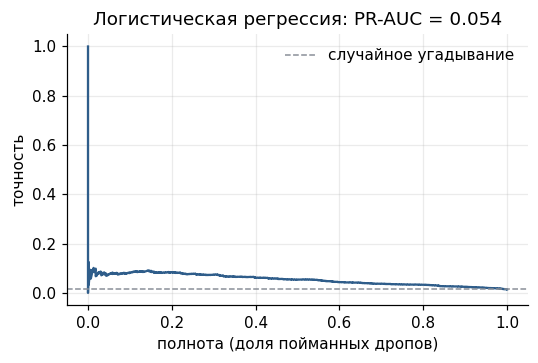

In [19]:
report("Логистическая регрессия", s_logreg)

#### Веса признаков

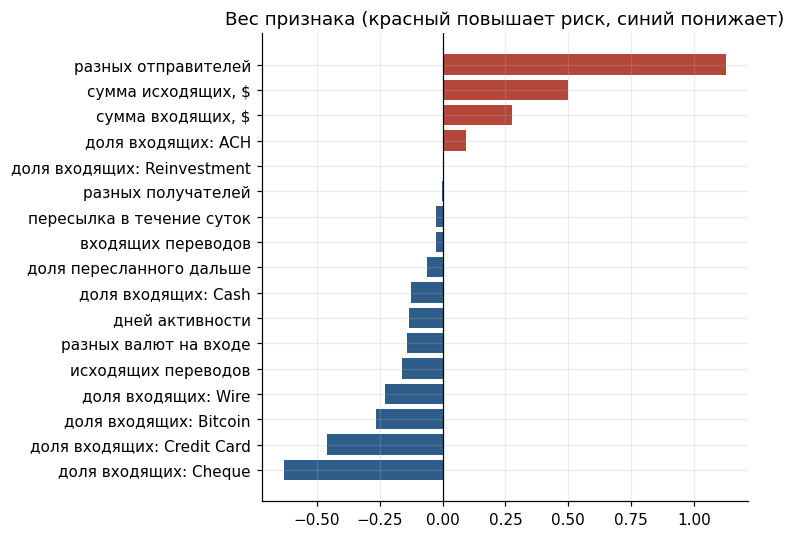

In [20]:
w = pd.Series(logreg.coef_[0], index=FEATURE_NAMES).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(w.index, w.values, color=[RED if v > 0 else BLUE for v in w.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Вес признака (красный повышает риск, синий понижает)")
plt.tight_layout(); plt.show()

Логистическая регрессия лучше ранжирует счета в целом, а в топ-100 и при ограничении ложных тревог примерно до 1% результаты совпали.

| Метрика на тесте | Простое правило | Логистическая регрессия |
|---|---:|---:|
| PR-AUC (Average Precision) | 0,033 | **0,054** |
| ROC-AUC | 0,679 | **0,799** |
| Полнота при 1% ложных тревог | 5,9% | 5,9% |
| Дропов среди 100 счетов с наибольшим риском | 9 | 9 |

Регрессия поймала 121 из 598 дропов (20,2%), а правило 52 из 598 (8,7%). Вместе с этим число ложных тревог выросло с 753 до 1 339. Доля подтверждённых тревог тоже выросла с 6,5% до 8,3%. То есть регрессия нашла на 69 дропов больше, ценой 586 дополнительных ложных тревог.

---
## Модель 2: градиентный бустинг

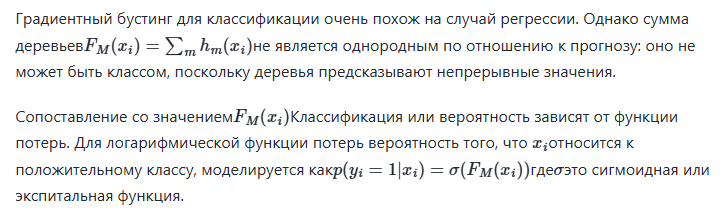

[https://scikit-learn.org/stable/modules/ensemble.html#mathematical-formulation]

В нашем случае модель строит много небольших деревьев решений. Каждое следующее дерево исправляет ошибки уже построенных. Итоговая оценка строится из суммы ответов всех деревьев.

Модель работает с 17 признаками самого счёта и средними признаками его соседей. Всего 51 число:

- 17 – сам счёт;
- 17 – среднее по всем, **кто отправлял** деньги на этот счёт;
- 17 – среднее по всем, **кому** этот счёт отправлял.

#### Средние признаки соседей

In [21]:
def mean_adjacency(edges, n, reverse):
    rows, cols = (edges[:, 1], edges[:, 0]) if not reverse else (edges[:, 0], edges[:, 1])
    deg = np.bincount(rows, minlength=n).astype(np.float32)
    vals = 1.0 / np.maximum(deg[rows], 1)
    idx = torch.tensor(np.stack([rows, cols]), dtype=torch.long)
    return torch.sparse_coo_tensor(idx, torch.tensor(vals), (n, n)).coalesce().to_sparse_csr()

A_in, A_out = mean_adjacency(edges, N, False), mean_adjacency(edges, N, True)
xt = torch.tensor(x)
with torch.no_grad():
    x_senders, x_receivers = (A_in @ xt).numpy(), (A_out @ xt).numpy()
x_graph = np.concatenate([x, x_senders, x_receivers], 1)
GB_NAMES = FEATURE_NAMES + ["отправители: " + f for f in FEATURE_NAMES] + ["получатели: " + f for f in FEATURE_NAMES]
print("Признаков для бустинга:", x_graph.shape[1])

/tmp/ipykernel_433/1877993898.py:6: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(idx, torch.tensor(vals), (n, n)).coalesce().to_sparse_csr()
/tmp/ipykernel_433/1877993898.py:6: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  return torch.sparse_coo_tensor(idx, torch.tensor(vals), (n, n)).coalesce().to_sparse_csr()


Признаков для бустинга: 51


Каждая строка edges – это пара [отправитель, получатель]. В матрицах, которые строит функция, строка обозначает счёт, для которого считаем среднее, а столбец его соседа. Поэтому для перевода B -> A:
- В A_in связь попадёт в строку A, столбец B. Когда считаем признаки для A, берём его отправителя B.
- В A_out связь попадёт в строку B, столбец A. Когда считаем признаки для B, берём его получателя A.

Дальше усредняем соседей. np.bincount считает, сколько соседей приходится на каждую строку. vals присваивает каждому соседу вес 1/число соседей. Например, если на счёт A переводили деньги B и C, оба получат вес 1/2. В edges уже оставлены уникальные пары счетов, поэтому каждый сосед учитывается один раз независимо от числа переводов между этой парой.

torch.sparse_coo_tensor(...) создаёт разреженную матрицу размера N*N. xt = torch.tensor(x) превращает исходную матрицу признаков в тензор. Затем @ выполняет матричное умножение. np.concatenate склеивает три блока по столбцам. На каждый счёт остаётся одна строка с 17 собственными + 17 усреднёнными по отправителям + 17 усреднёнными по получателям = 51 признаком.

#### Параметры бустинга

In [22]:
USE_NEIGHBORS = True  # @param {type:"boolean"}
GB_MAX_ITER = 300  # @param {type:"integer"}
GB_LEARNING_RATE = 0.1  # @param {type:"number"}
GB_MAX_LEAF_NODES = 31  # @param {type:"integer"}
GB_EARLY_STOPPING = True  # @param {type:"boolean"}

*   USE_NEIGHBORS: при True бустинг получает 51 признак с учётом средних по соседям, при False 17 признаков самого счёта.
*   max_iter: Максимум 300 итераций.
*   learning_rate: Насколько сильно каждое новое дерево поправляет предыдущие. Вклад каждого нового дерева умножается на 0.1.
*   max_leaf_nodes: Максимум 31 лист в каждом дереве.
*   early_stopping: Досрочная остановка, если за последние 10 итераций не было достаточного улучшения log_loss

[https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html]

#### Обучение

In [23]:
X_GB = x_graph if USE_NEIGHBORS else x
t0 = time.time()
gb = HistGradientBoostingClassifier(max_iter=GB_MAX_ITER, learning_rate=GB_LEARNING_RATE, max_leaf_nodes=GB_MAX_LEAF_NODES, early_stopping=GB_EARLY_STOPPING, class_weight="balanced", random_state=SEED)
gb.fit(X_GB[tr], y[tr])
print(f"Обучено за {time.time() - t0:.0f} с, построено деревьев: {gb.n_iter_} из {GB_MAX_ITER}")
s_boost = gb.predict_proba(X_GB)[:, 1]

Обучено за 9 с, построено деревьев: 63 из 300


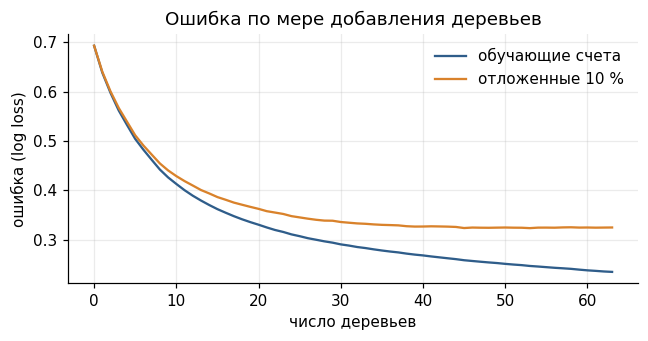

In [24]:
if GB_EARLY_STOPPING:
    plt.figure(figsize=(6, 3.2))
    plt.plot(-gb.train_score_, color=BLUE, label="обучающие счета")
    plt.plot(-gb.validation_score_, color=ORANGE, label="отложенные 10 %")
    plt.xlabel("число деревьев"); plt.ylabel("ошибка (log loss)")
    plt.title("Ошибка по мере добавления деревьев"); plt.legend(frameon=False)
    plt.tight_layout(); plt.show()

#### Результат на тесте

PR-AUC                   0.338
ROC-AUC                  0.935
полнота при 1% ложных    0.318
точность топ-100         0.960

Решение на пороге (тестовые счета):
порог                  0.898173
поймано дропов              159
пропущено дропов            439
ложных тревог               186
обычных без тревоги       41876


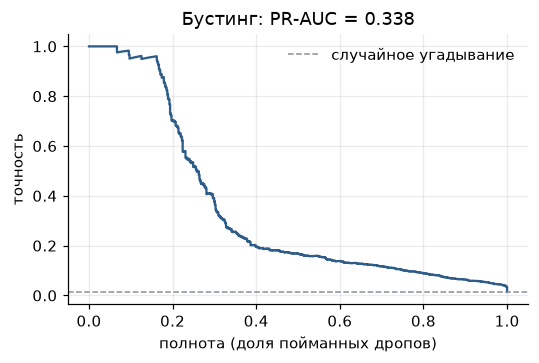

In [ ]:
report("Бустинг" + ("" if USE_NEIGHBORS else " без соседей"), s_boost)

#### Важность признаков

Важность признака измеряем перестановкой: перемешиваем один признак между тестовыми счетами и смотрим, насколько упал PR-AUC. Чем сильнее падение, тем больше модель на этот признак опирается.

[https://scikit-learn.org/stable/modules/permutation_importance.html#outline-of-the-permutation-importance-algorithm]

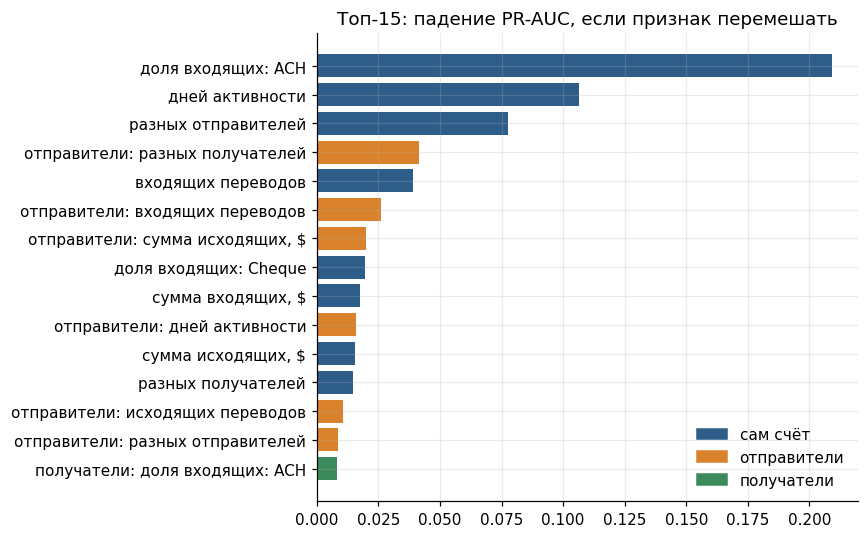

In [25]:
rng = np.random.default_rng(SEED)
names = GB_NAMES if USE_NEIGHBORS else FEATURE_NAMES
Xte = X_GB[te]
base = average_precision_score(y[te], gb.predict_proba(Xte)[:, 1])
drop = []
for j in range(Xte.shape[1]):
    xp = Xte.copy()
    xp[:, j] = xp[rng.permutation(len(xp)), j]
    drop.append(base - average_precision_score(y[te], gb.predict_proba(xp)[:, 1]))
imp = pd.Series(drop, index=names).sort_values(ascending=False).head(15)[::-1]

color = [ORANGE if n.startswith("отправители") else GREEN if n.startswith("получатели") else BLUE for n in imp.index]
plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values, color=color)
plt.title("Топ-15: падение PR-AUC, если признак перемешать")
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=BLUE, label="сам счёт"), Patch(color=ORANGE, label="отправители"), Patch(color=GREEN, label="получатели")], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

---
## 4. Модель 3: GraphSAGE

**Идея.** Бустингу мы сами дали средние по соседям. GraphSAGE сама учится, какую информацию собирать от соседей и как её смешивать со своей.

Название GraphSAGE – от английского SAmple and aggreGatE, «выбрать соседей и собрать их». В оригинальной статье* соседей выбирают случайно, чтобы граф с миллиардами рёбер помещался в память. Наш граф помещается целиком, поэтому мы берём всех соседей

*[https://arxiv.org/html/1706.02216v4]

Алгоритм GraphSAGE из оригинальной статьи:

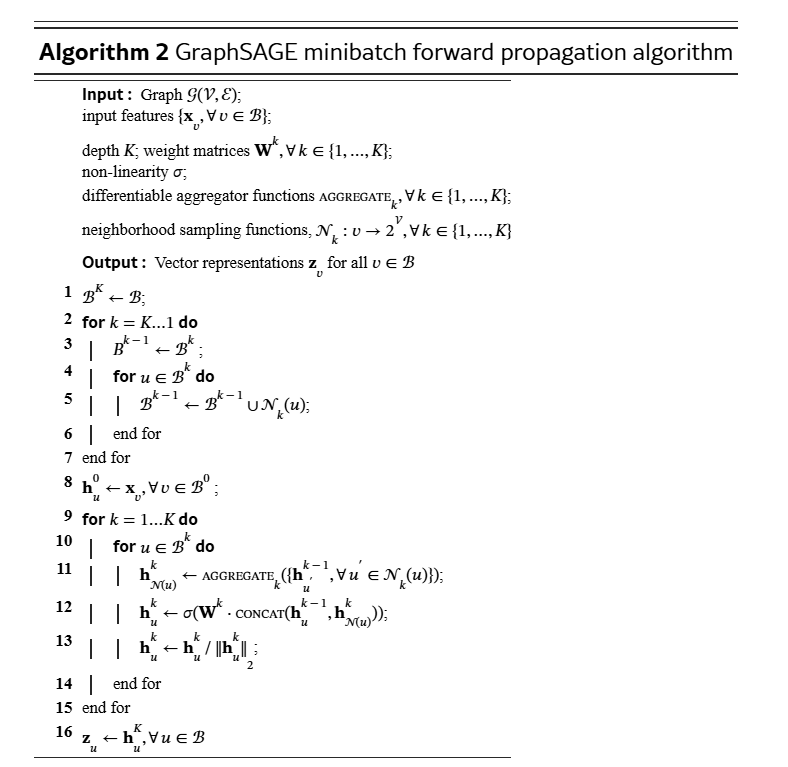

Один слой GraphSAGE для каждого счёта выполняет три действия:

*   Собрать (агрегировать). Взять векторы всех отправителей счёта и посчитать их среднее. Отдельно среднее по всем получателям. Среднее, необходимо для того, чтобы счёт с 3 соседями и счёт с 300 были сравнимы.
*   Смешать. Умножить три вектора: свой, средний отправитель и средний получатель – каждый на свою матрицу весов и сложить. Сеть учится этим весам: какие сочетания признаков у себя и у соседей важны.
*   ReLU добавляет нелинейность. Без неё несколько слоёв схлопнулись бы в один.

**Формула для нашего случая:**

$$h_v' = \mathrm{ReLU}\big(\,W_0\,h_v \;+\; W_{in}\cdot\text{среднее}(h_u : u \to v) \;+\; W_{out}\cdot\text{среднее}(h_u : v \to u)\,\big) (1)$$

- $h_v$ – текущее описание счёта (вначале это его 17 признаков);
- $W_0$, $W_{in}$, $W_{out}$ – матрицы весов, которые подбираются при обучении: что взять от себя, от отправителей, от получателей;
- ${среднее}(h_u : u \to v)$ – средний вектор отправителей, то есть счетов u, которые переводили деньги на счёт v.
- ${среднее}(h_u : v \to u)$ – средний вектор получателей, то есть счетов u, которым счёт v переводил деньги.
- отправители и получатели учитываются раздельно, потому что направление денег важно.

В конце выходной слой GraphSAGE, или «голова» классификатора умножает каждое из 64 чисел на свой обучаемый вес, складывает результаты и добавляет смещение c, чтобы получить логит. Сигмоида переводит его в итоговую оценку вероятности класса «дроп» от 0 до 1.

$$
p_v = \sigma\!\left(\mathbf{w}_{\mathrm{head}}^{\top}
                    \mathbf{h}_v^{(2)} + c\right),
\qquad
\sigma(z) = \frac{1}{1 + e^{-z}}.
$$

Здесь $\mathbf{h}_v^{(2)}$ – представление счёта из 64 чисел,
$\mathbf{w}_{\mathrm{head}}$ – обучаемые веса выходного слоя,
а $c$ – его свободный член.

[https://docs.pytorch.org/docs/2.15/generated/torch.nn.Linear.html]

[https://docs.pytorch.org/docs/2.15/generated/torch.nn.Sigmoid.html]

**Обучение:** Каждая эпоха – это один проход по всему графу: сеть считает оценки, сравниваются с метками обучающих счетов, веса чуть поправляются (оптимизатор Adam). Каждые 5 эпох смотрим PR-AUC на проверке и запоминаем лучшее состояние сети.

После первого слоя вектор каждого счёта содержит сведения о его прямых соседях. Второй слой снова усредняет соседей, но их векторы уже содержат их собственных соседей. Значит, после двух слоёв счёт видит на два шага: отправителей своих отправителей, получателей своих получателей и так далее.

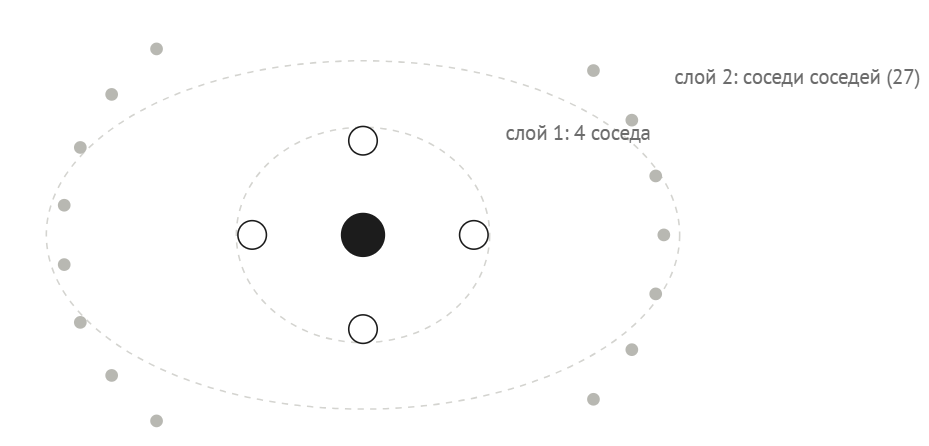

### Как GraphSAGE видит наш граф

Формулу выше удобнее понять на картинке. Ниже — настоящий счёт-дроп из тестовой выборки и его окрестность в графе переводов. Деньги на рисунках текут слева направо: слева те, кто присылал деньги, справа — те, кому счёт пересылал.

Идея рисунков взята из статьи Distill «A Gentle Introduction to Graph Neural Networks», но все точки и стрелки здесь — счета и переводы из нашего датасета.

[https://distill.pub/2021/gnn-intro/]

In [ ]:
# @title Соседи каждого счёта и функции рисования
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D

E_SRC, E_DST = edges[:, 0], edges[:, 1]
_ord_in = np.argsort(E_DST, kind="stable")
_ptr_in = np.searchsorted(E_DST[_ord_in], np.arange(N + 1))
_ord_out = np.argsort(E_SRC, kind="stable")
_ptr_out = np.searchsorted(E_SRC[_ord_out], np.arange(N + 1))

def senders_of(v):
    """Кто присылал деньги на счёт v."""
    return E_SRC[_ord_in[_ptr_in[v]:_ptr_in[v + 1]]]

def receivers_of(v):
    """Кому счёт v отправлял деньги."""
    return E_DST[_ord_out[_ptr_out[v]:_ptr_out[v + 1]]]

def ego_columns(v, per_col=9, seed=0):
    """Окрестность счёта v по столбцам: -2 отправители отправителей, -1 отправители, 0 сам счёт,
    1 получатели, 2 получатели получателей. Если соседей много, показываем случайные per_col."""
    r_ = np.random.default_rng(seed)
    def cap(a):
        a = np.unique(np.asarray(a, dtype=np.int64))
        return np.sort(r_.choice(a, per_col, replace=False)) if len(a) > per_col else a
    s1, r1 = cap(senders_of(v)), cap(receivers_of(v))
    near = np.concatenate([[v], s1, r1])
    s2 = cap(np.setdiff1d(np.concatenate([senders_of(u) for u in s1] + [np.empty(0, np.int64)]), near))
    r2 = cap(np.setdiff1d(np.concatenate([receivers_of(u) for u in r1] + [np.empty(0, np.int64)]), near))
    return {-2: s2, -1: s1, 0: np.array([v]), 1: r1, 2: r2}

COL_TITLES = {-2: "отправители\nотправителей", -1: "отправители", 0: "счёт", 1: "получатели", 2: "получатели\nполучателей"}

def draw_ego(ax, cols, node_color, focus=None, title="", col_titles=True, ring=None):
    """Рисует окрестность. node_color(u) -> цвет; focus — какие счета яркие (остальные бледные);
    ring — счета, которые обвести чёрным (настоящие дропы)."""
    pos = {}
    for k, nodes in cols.items():
        for i, u in enumerate(nodes):
            pos[int(u)] = (k, (i - (len(nodes) - 1) / 2) * 0.8)
    drawn = set(pos)
    for u in drawn:                                   # стрелки только между нарисованными счетами
        for w in receivers_of(u):
            w = int(w)
            if w in drawn and w != u:
                lit = focus is None or (u in focus and w in focus)
                ax.add_patch(FancyArrowPatch(pos[u], pos[w], arrowstyle="-|>", mutation_scale=9,
                                             shrinkA=7, shrinkB=7, lw=0.9, color="#55606e",
                                             alpha=0.55 if lit else 0.08, connectionstyle="arc3,rad=0.06"))
    for u, (px, py) in pos.items():
        lit = focus is None or u in focus
        center = px == 0
        ax.scatter(px, py, s=260 if center else 110, color=node_color(u), alpha=1 if lit else 0.15,
                   edgecolor="black" if (ring is not None and u in ring) else "white",
                   linewidth=1.6 if (ring is not None and u in ring) else 0.8, zorder=3)
    hmax = max(len(n) for n in cols.values())
    ax.set_xlim(-2.6, 2.6); ax.set_ylim(-(hmax / 2) * 0.8 - 0.3, (hmax / 2) * 0.8 + 0.9)
    if col_titles:
        for k, t in COL_TITLES.items():
            ax.text(k, (hmax / 2) * 0.8 + 0.25, t, ha="center", va="bottom", fontsize=8, color="#55606e")
    ax.set_title(title, fontsize=10); ax.axis("off")

Счёт 0223:811B9B160: отправителей 6, получателей 3, метка: дроп
На рисунке: {'отправители отправителей': 9, 'отправители': 6, 'счёт': 1, 'получатели': 3, 'получатели получателей': 9}


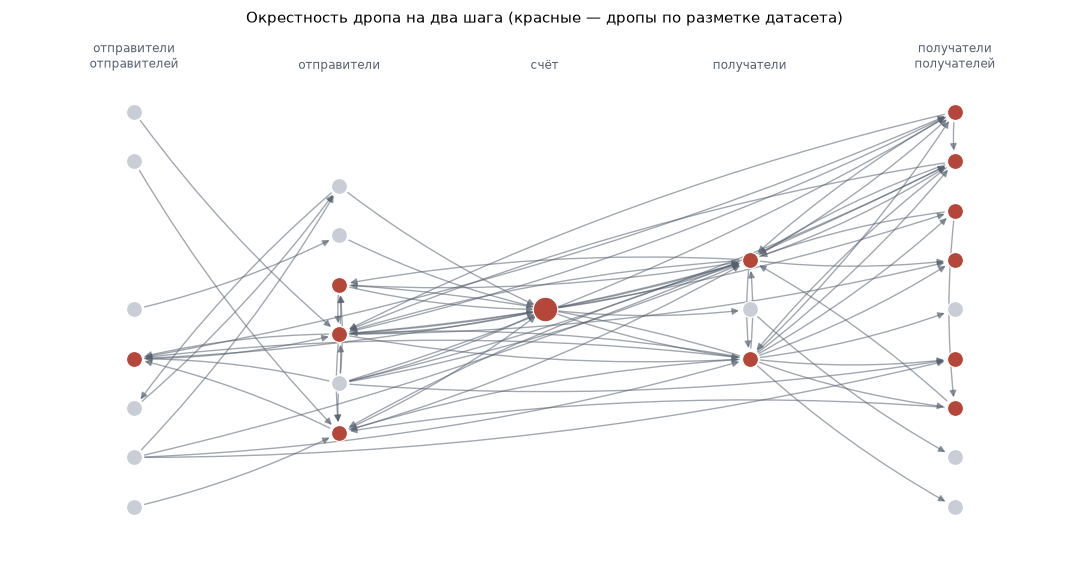

In [ ]:
# @title Выбираем дроп из тестовой выборки
indeg_all = np.bincount(E_DST, minlength=N)
outdeg_all = np.bincount(E_SRC, minlength=N)
cand = np.where(te & (y == 1) & (indeg_all >= 3) & (indeg_all <= 7) & (outdeg_all >= 1) & (outdeg_all <= 3))[0]
# берём того, у кого окрестность на два шага самая наполненная — так картинка нагляднее
fill = [sum(len(c) for c in ego_columns(v).values()) for v in cand[:400]]
EGO_V = int(cand[int(np.argmax(fill))])
EGO = ego_columns(EGO_V)
print(f"Счёт {keys[EGO_V]}: отправителей {indeg_all[EGO_V]}, получателей {outdeg_all[EGO_V]}, метка: дроп")
print("На рисунке:", {COL_TITLES[k].replace(chr(10), ' '): len(v) for k, v in EGO.items()})

lab_color = lambda u: RED if y[u] == 1 else ("#c9ced6" if u != EGO_V else RED)
fig, ax = plt.subplots(figsize=(10, 5.2))
draw_ego(ax, EGO, lab_color, title="Окрестность дропа на два шага (красные — дропы по разметке датасета)")
plt.tight_layout(); plt.show()

#### Поле зрения растёт с каждым слоем

Один слой GraphSAGE смешивает счёт с его **прямыми** соседями. Второй слой делает то же ещё раз — но соседи к этому моменту уже содержат сведения о **своих** соседях. Поэтому после двух слоёв описание счёта зависит от всех счетов на расстоянии до двух переводов.

На рисунке яркие точки — счета, от которых зависит описание центрального счёта после 0, 1 и 2 слоёв. Для наглядности показаны только две ветви (отправители отправителей и получатели получателей); на самом деле второй слой захватывает и «получателей отправителей», и «отправителей получателей».

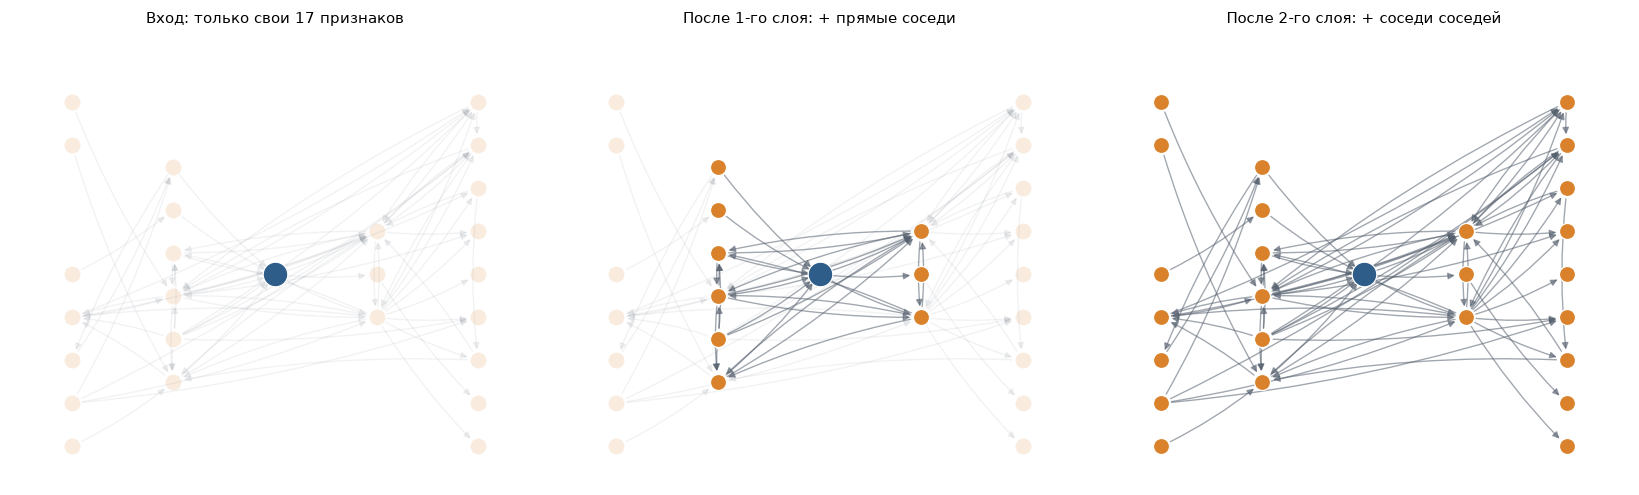

In [ ]:
# @title Три картинки: до слоёв, после 1-го, после 2-го
hop1 = {EGO_V} | set(EGO[-1].tolist()) | set(EGO[1].tolist())
hop2 = hop1 | set(EGO[-2].tolist()) | set(EGO[2].tolist())
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, focus) in zip(axs, [("Вход: только свои 17 признаков", {EGO_V}),
                                    ("После 1-го слоя: + прямые соседи", hop1),
                                    ("После 2-го слоя: + соседи соседей", hop2)]):
    draw_ego(ax, EGO, lambda u: BLUE if u == EGO_V else ORANGE, focus=focus, title=title, col_titles=False)
plt.tight_layout(); plt.show()

#### Что слой получает на вход для этого счёта

Шаг «собрать» из формулы (1): для счёта берутся три вектора по 17 чисел — свой, **средний по всем отправителям** и **средний по всем получателям**. Ниже они для выбранного дропа (признаки после логарифма и стандартизации: 0 — как у среднего счёта, +1 — на одно стандартное отклонение выше).

Слой умножает каждый из трёх векторов на свою матрицу весов ($W_0$, $W_{in}$, $W_{out}$) и складывает. Эти же средние мы вручную давали бустингу (`x_senders`, `x_receivers`).

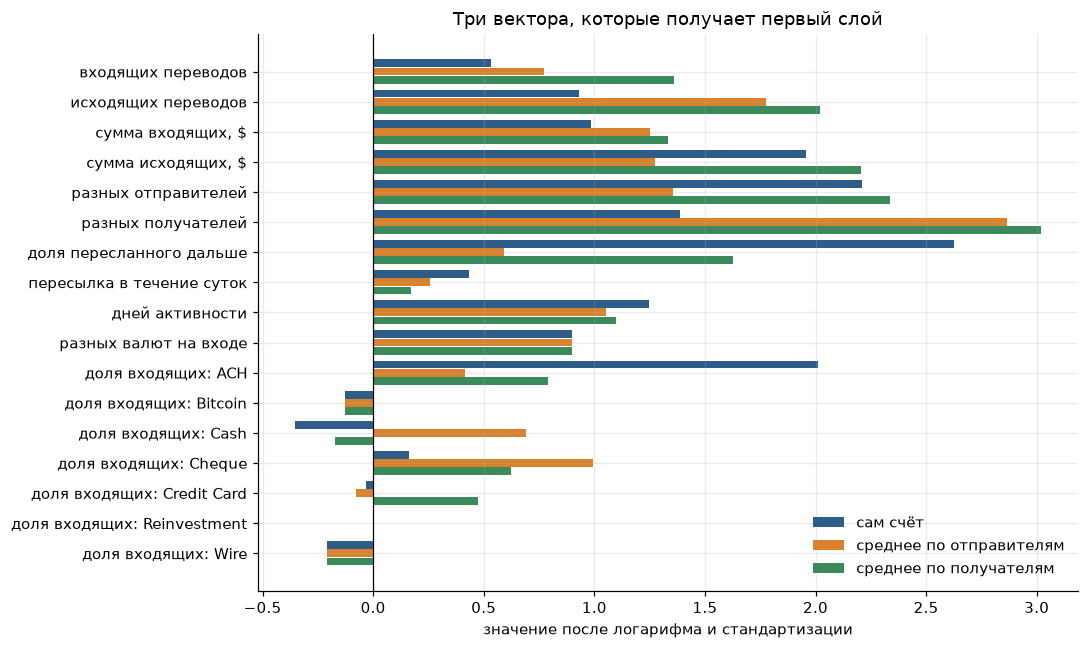

In [ ]:
# @title Свой вектор и средние по соседям
vals = pd.DataFrame({"сам счёт": x[EGO_V], "среднее по отправителям": x_senders[EGO_V],
                     "среднее по получателям": x_receivers[EGO_V]}, index=FEATURE_NAMES)
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(vals))
for k, (col, colr) in enumerate(zip(vals.columns, [BLUE, ORANGE, GREEN])):
    ax.barh(yy + (k - 1) * 0.27, vals[col], height=0.26, color=colr, label=col)
ax.set_yticks(yy); ax.set_yticklabels(vals.index); ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("значение после логарифма и стандартизации")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Три вектора, которые получает первый слой")
plt.tight_layout(); plt.show()

#### Почему без графа не обойтись: схемы отмывания

Кроме таблицы переводов, авторы датасета выложили файл `HI-Small_Patterns.txt`: в нём перечислены операции отмывания и схема каждой (веер, цикл, разброс-сбор и т. д. — те же, что на рисунке «Шаблоны AML» выше). Нарисуем по одному **настоящему** примеру каждой схемы из этого файла.

Каждая схема — это форма в графе. Если смотреть на один счёт, формы не видно: счёт в середине цикла выглядит как обычный «получил — переслал». Видно её только по связям.

Файл маленький (300 КБ), ячейка скачивает его сама.

In [ ]:
# @title Скачать и разобрать HI-Small_Patterns.txt
import re
PATTERNS_URL = "https://huggingface.co/datasets/OsamaMIT/IBM-AML-HI/resolve/main/HI-Small_Patterns.txt"
PATTERNS_PATH = "HI-Small_Patterns.txt"
if not os.path.exists(PATTERNS_PATH):
    urllib.request.urlretrieve(PATTERNS_URL, PATTERNS_PATH)

SCHEMES = {
    "FAN-IN": "Веер на вход", "FAN-OUT": "Веер на выход", "CYCLE": "Цикл",
    "SCATTER-GATHER": "Разброс-сбор", "GATHER-SCATTER": "Сбор-разброс",
    "BIPARTITE": "Двудольная", "STACK": "Стопка", "RANDOM": "Случайная",
}
attempts, cur_att = [], None
with open(PATTERNS_PATH, encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line.startswith("BEGIN LAUNDERING ATTEMPT"):
            cur_att = {"type": re.match(r"BEGIN LAUNDERING ATTEMPT - ([A-Z-]+)", line).group(1), "txns": []}
        elif line.startswith("END LAUNDERING ATTEMPT"):
            attempts.append(cur_att); cur_att = None
        elif cur_att is not None and line[:2] == "20":
            p_ = line.split(",")
            cur_att["txns"].append((p_[1] + ":" + p_[2], p_[3] + ":" + p_[4]))

key_index = {k: i for i, k in enumerate(keys)}
in_patterns = sum(len(a["txns"]) for a in attempts)
print(f"Операций отмывания в файле: {len(attempts)}, переводов в них: {in_patterns} из {int(ill.sum())} помеченных в датасете")
pd.Series([SCHEMES[a["type"]] for a in attempts]).value_counts().rename("операций").to_frame()

Операций отмывания в файле: 370, переводов в них: 3209 из 5177 помеченных в датасете


,операций
Цикл,54
Сбор-разброс,51
Двудольная,49
Веер на выход,48
Разброс-сбор,44
Стопка,43
Случайная,41
Веер на вход,40


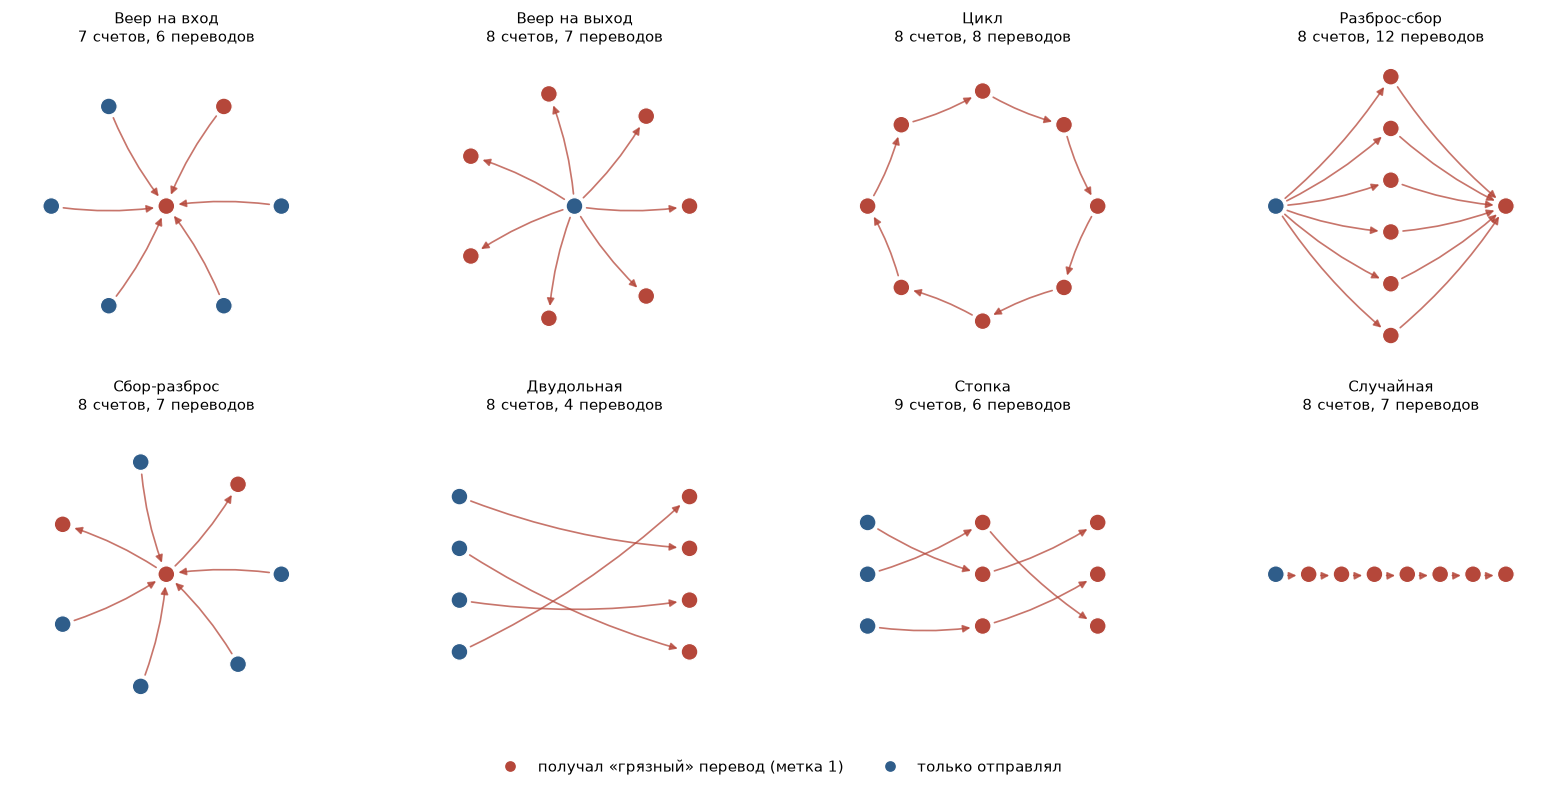

In [ ]:
# @title Восемь схем — по одному настоящему примеру
def scheme_layout(nodes, arcs):
    """Расстановка точек: «звезда», если один счёт связан со всеми; круг, если есть цикл; иначе слоями слева направо."""
    nodes = list(nodes); n = len(nodes)
    deg = {u: 0 for u in nodes}
    for a, b in arcs:
        deg[a] += 1; deg[b] += 1
    hub = max(nodes, key=lambda u: deg[u])
    indeg = {u: 0 for u in nodes}
    for a, b in arcs:
        indeg[b] += 1
    if deg[hub] >= n - 1 and n > 3:                         # веер
        others = [u for u in nodes if u != hub]
        ang = np.linspace(0, 2 * np.pi, len(others), endpoint=False)
        return {hub: (0, 0), **{u: (np.cos(t), np.sin(t)) for u, t in zip(others, ang)}}
    if not any(indeg[u] == 0 for u in nodes):               # цикл
        order, u = [], nodes[0]
        nxt = {a: b for a, b in arcs}
        while u not in order and u in nxt:
            order.append(u); u = nxt[u]
        order += [u for u in nodes if u not in order]
        ang = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(order), endpoint=False)
        return {u: (np.cos(t), np.sin(t)) for u, t in zip(order, ang)}
    level = {u: 0 for u in nodes}                           # слои: длина самого длинного пути от источника
    for _ in range(n):
        for a, b in arcs:
            level[b] = max(level[b], level[a] + 1)
    pos, by_lvl = {}, {}
    for u in nodes:
        by_lvl.setdefault(level[u], []).append(u)
    L = max(by_lvl)
    for l, us in by_lvl.items():
        for i, u in enumerate(us):
            pos[u] = (-1 + 2 * l / max(L, 1), (i - (len(us) - 1) / 2) * 0.45)
    return pos

fig, axs = plt.subplots(2, 4, figsize=(15, 7.2))
for ax, code_ in zip(axs.ravel(), SCHEMES):
    cands = [a for a in attempts if a["type"] == code_]
    sizes = [len({u for t in a["txns"] for u in t}) for a in cands]
    a = cands[int(np.argmin([abs(s - 8) for s in sizes]))]   # пример размером около 8 счетов — читается лучше всего
    arcs = sorted({t for t in a["txns"] if t[0] != t[1]})
    nodes = sorted({u for t in arcs for u in t})
    pos = scheme_layout(nodes, arcs)
    for s_, d_ in arcs:
        ax.add_patch(FancyArrowPatch(pos[s_], pos[d_], arrowstyle="-|>", mutation_scale=10, shrinkA=8, shrinkB=8,
                                     lw=1.1, color=RED, alpha=0.75, connectionstyle="arc3,rad=0.08"))
    is_drop = [y[key_index[u]] == 1 if u in key_index else False for u in nodes]
    ax.scatter([pos[u][0] for u in nodes], [pos[u][1] for u in nodes], s=120, zorder=3,
               color=[RED if d else BLUE for d in is_drop], edgecolor="white", linewidth=0.8)
    ax.set_title(f"{SCHEMES[code_]}\n{len(nodes)} счетов, {len(a['txns'])} переводов", fontsize=10)
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.axis("off")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=RED, label="получал «грязный» перевод (метка 1)"),
                    Line2D([], [], marker="o", ls="", color=BLUE, label="только отправлял")],
           loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

#### Устройство сети

In [ ]:
class SageLayer(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.in_lin = nn.Linear(d_in, d_out, bias=False)
        self.out_lin = nn.Linear(d_in, d_out, bias=False)

    def forward(self, h, a_in, a_out):
        return self.self_lin(h) + self.in_lin(a_in @ h) + self.out_lin(a_out @ h)


class GraphSAGE(nn.Module):
    def __init__(self, d_in, hidden, layers, dropout):
        super().__init__()
        dims = [d_in] + [hidden] * layers
        self.layers = nn.ModuleList(SageLayer(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, a_in, a_out):
        h = x
        for layer in self.layers:
            h = self.drop(torch.relu(layer(h, a_in, a_out)))
        return self.head(h).squeeze(-1)

Параметры (веса) – это числа внутри матриц W и векторов b. До обучения они случайные, после обучения такие, при которых сеть лучше всего отличает дропов. Для итоговой оценки используется состояние модели с наибольшей Average Precision среди проверенных эпох. [https://docs.pytorch.org/docs/2.15/generated/torch.nn.Linear.html]

Всего в нашей сети 15 745 параметров:

| Часть модели | Расчёт | Параметров |
|---|---:|---:|
| Первый графовый слой | 3&nbsp;×&nbsp;64&nbsp;×&nbsp;17&nbsp;+&nbsp;64 | 3 328 |
| Второй графовый слой | 3&nbsp;×&nbsp;64&nbsp;×&nbsp;64&nbsp;+&nbsp;64 | 12 352 |
| Выходной слой | 1&nbsp;×&nbsp;64&nbsp;+&nbsp;1 | 65 |
| **Итого** | | **15 745** |

Для сравнения: в языковых моделях миллиарды параметров. Данная сеть на входе имеет всего 17 признаков. Веса одни и те же для всех 515 тысяч счетов. Сеть учит не счета, а правило, как смешивать признаки себя и соседей. Поэтому её можно применить к новому счёту, которого не было при обучении. Эта характеристика описана в статье* как индуктивность

*[https://arxiv.org/html/1706.02216v4]

#### Параметры GraphSAGE

In [ ]:
EPOCHS = 300  # @param {type:"integer"}
HIDDEN = 64  # @param {type:"integer"}
LAYERS = 2  # @param {type:"integer"}
LR = 0.02  # @param {type:"number"}
DROPOUT = 0.2  # @param {type:"number"}
WEIGHT_DECAY = 1e-5  # @param {type:"number"}

EPOCHS – эпохи – количество проходов по графу.

HIDDEN – длина описания счёта внутри сети (сколько чисел). Чем больше, тем сеть умнее, но легче запоминает шум.

LAYERS – количество слоёв: 1 – только прямые соседи, 2 – соседи соседей, 3 – ещё дальше.

LR – шаг обучения: насколько сильно поправлять веса за эпоху. Если взять слишком большой, обучение будет скакать, если слишком маленький – идти медленно.

DROPOUT – доля чисел, которые случайно забываются при обучении

WEIGHT_DECAY – штраф за большие веса (то же, что регуляризация у регрессии).

#### Обучение

4 шага обучения:

*   **Прямой проход**. Сеть проходит по всему графу. Два графовых слоя обновляют представление каждого счёта, а выходной слой выдаёт по одному логиту. По формуле (1).
*   **Ошибка (функция потерь)**. Для каждого обучающего счёта сравниваем оценку с правильным ответом (0 – честный, 1 – дроп) по формуле бинарной кросс-энтропии:

$$
\text{ошибка} = -\left[
p \cdot y \cdot \log(\text{оценка}) + (1-y) \cdot \log(1-\text{оценка})
\right]
$$

[https://docs.pytorch.org/docs/2.15/generated/torch.nn.BCEWithLogitsLoss.html]

Если дроп получил оценку 0,99 – ошибка почти 0; если 0,01 – ошибка большая. Дропов в 70 раз меньше, чем честных счетов, поэтому ошибка на дропе умножается на p ≈ 70 (pos_weight). Иначе сети было бы выгодно всем отвечать «честный».

*   **Подправить веса**. Алгоритм обратного распространения считает, в какую сторону сдвинуть каждый из параметров, чтобы ошибка уменьшилась. Оптимизатор Adam делает небольшой шаг в эту сторону (размер шага – скорость обучения, 0,02).
*   **Повтор**. Один такой круг – эпоха. Их 300. Каждые 5 эпох считаем PR-AUC на проверочных счетах (их сеть не видит при подстройке весов) и запоминаем лучшие веса.

In [ ]:
torch.manual_seed(SEED)
model = GraphSAGE(x.shape[1], HIDDEN, LAYERS, DROPOUT).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

X_t = torch.tensor(x).to(DEVICE)
a_in, a_out = A_in.to(DEVICE), A_out.to(DEVICE)
y_t = torch.tensor(y, dtype=torch.float32).to(DEVICE)
tr_t = torch.tensor(tr).to(DEVICE)
va_idx = np.where(va)[0]
pos_weight = torch.tensor((y[tr] == 0).sum() / max(1, (y[tr] == 1).sum()), dtype=torch.float32).to(DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

best, best_state, curve = -1.0, None, []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train(); opt.zero_grad()
    logits = model(X_t, a_in, a_out)
    loss = loss_fn(logits[tr_t], y_t[tr_t])
    loss.backward(); opt.step()
    if epoch % 5 == 0 or epoch == EPOCHS:
        model.eval()
        with torch.no_grad():
            sv = torch.sigmoid(model(X_t, a_in, a_out)).cpu().numpy()
        val_ap = average_precision_score(y[va_idx], sv[va_idx])
        curve.append((epoch, loss.item(), val_ap))
        if val_ap > best:
            best, best_epoch = val_ap, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch % 25 == 0 or epoch == EPOCHS:
            print(f"эпоха {epoch:4d}   ошибка {loss.item():.4f}   PR-AUC на проверке {val_ap:.3f}   ({time.time() - t0:.0f} с)")

model.load_state_dict(best_state); model.eval()
with torch.no_grad():
    s_sage = torch.sigmoid(model(X_t, a_in, a_out)).cpu().numpy()
print(f"\nЛучшая эпоха: {best_epoch} (PR-AUC на проверке {best:.3f}). Берём состояние сети с этой эпохи.")

эпоха   25   ошибка 0.9387   PR-AUC на проверке 0.080   (66 с)


эпоха   50   ошибка 0.7674   PR-AUC на проверке 0.123   (131 с)


эпоха   75   ошибка 0.6690   PR-AUC на проверке 0.170   (194 с)


эпоха  100   ошибка 0.5967   PR-AUC на проверке 0.223   (258 с)


эпоха  125   ошибка 0.5684   PR-AUC на проверке 0.251   (321 с)


эпоха  150   ошибка 0.5337   PR-AUC на проверке 0.290   (385 с)


... (3 outputs left out)

эпоха  250   ошибка 0.4969   PR-AUC на проверке 0.316   (643 с)


эпоха  275   ошибка 0.4761   PR-AUC на проверке 0.329   (707 с)


эпоха  300   ошибка 0.4536   PR-AUC на проверке 0.341   (772 с)



Лучшая эпоха: 300 (PR-AUC на проверке 0.341). Берём состояние сети с этой эпохи.


#### Как шло обучение

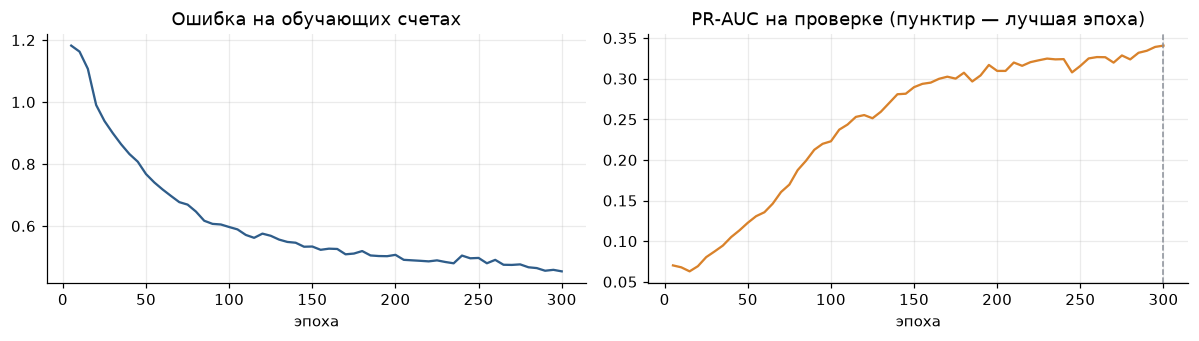

In [ ]:
c = np.array(curve)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(c[:, 0], c[:, 1], color=BLUE); ax[0].set_title("Ошибка на обучающих счетах"); ax[0].set_xlabel("эпоха")
ax[1].plot(c[:, 0], c[:, 2], color=ORANGE); ax[1].axvline(best_epoch, color=GREY, ls="--", lw=1)
ax[1].set_title("PR-AUC на проверке (пунктиром обозначена лучшая эпоха)"); ax[1].set_xlabel("эпоха")
plt.tight_layout(); plt.show()

#### Результат на тесте

PR-AUC                   0.375
ROC-AUC                  0.933
полнота при 1% ложных    0.385
точность топ-100         0.890

Решение на пороге (тестовые счета):
порог                  0.954094
поймано дропов              185
пропущено дропов            413
ложных тревог               162
обычных без тревоги       41900


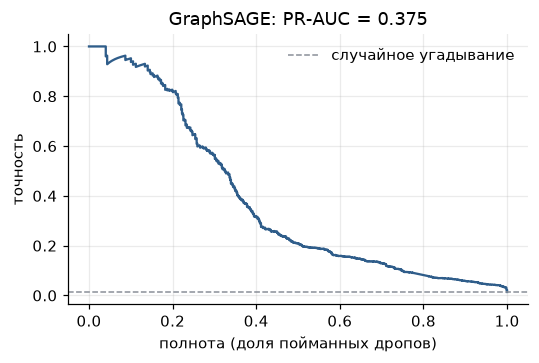

In [ ]:
report("GraphSAGE", s_sage)

---
### Что выучила сеть

Дальше — разделы 15–17 из учебника лаборатории и карта представлений, но на только что обученной сети из этого блокнота:

- **от оценки к решению** — калибровка и пороги;
- **что даёт граф** — «закрываем сети глаза»;
- **на какие признаки опирается сеть**;
- **карта, которую выучила нейросеть** (t-SNE);
- **какие схемы отмывания сеть находит**;
- **разбор настоящего счёта**.

Все ячейки ниже используют обученную модель `model` и оценки `s_sage` из ячеек выше. Если вы переобучили сеть с другими параметрами — просто перезапустите эти ячейки.

In [ ]:
# @title Прямой проход сети с возможностью «закрыть глаза»
def sage_forward(use_in=True, use_out=True, x_input=None, return_h=False):
    """То же, что model(...), но можно подать нули вместо среднего по отправителям (use_in=False)
    или по получателям (use_out=False). Возвращает оценку 0..1 для всех счетов (и, по желанию, 64 числа описания)."""
    h = X_t if x_input is None else x_input
    with torch.no_grad():
        for layer in model.layers:
            part_self = layer.self_lin(h)
            part_in = layer.in_lin(a_in @ h) if use_in else torch.zeros_like(part_self)
            part_out = layer.out_lin(a_out @ h) if use_out else torch.zeros_like(part_self)
            h = torch.relu(part_self + part_in + part_out)
        score = torch.sigmoid(model.head(h).squeeze(-1)).cpu().numpy()
    return (score, h.cpu().numpy()) if return_h else score

model.eval()
check = sage_forward()
print("Совпадает с оценками s_sage:", np.allclose(check, s_sage, atol=1e-5))

Совпадает с оценками s_sage: True


#### От оценки к решению

**Калибровка.** Сырая оценка сети — не вероятность. Ошибку на дропе мы умножали на ≈ 70 (`pos_weight`), поэтому сеть завышает оценки: у многих честных счетов они близки к 1. Чтобы оценка означала «из 100 таких счетов примерно столько-то дропов», по **проверочным** счетам строится изотоническая регрессия — монотонная «линейка перевода» сырой оценки в долю дропов.

[https://scikit-learn.org/stable/modules/isotonic.html]

**Пороги.** Банку нужно решение, а не число. Как в лаборатории, берём два порога, оба выбираются по проверочным счетам:

- **высокий риск** — порог с лучшим F1 (баланс пойманных дропов и ложных тревог);
- **повышенный риск** — порог, выше которого оказываются 5 % честных счетов проверки.

Порог «высокий риск»:   0.192
Порог «повышенный риск»: 0.0672


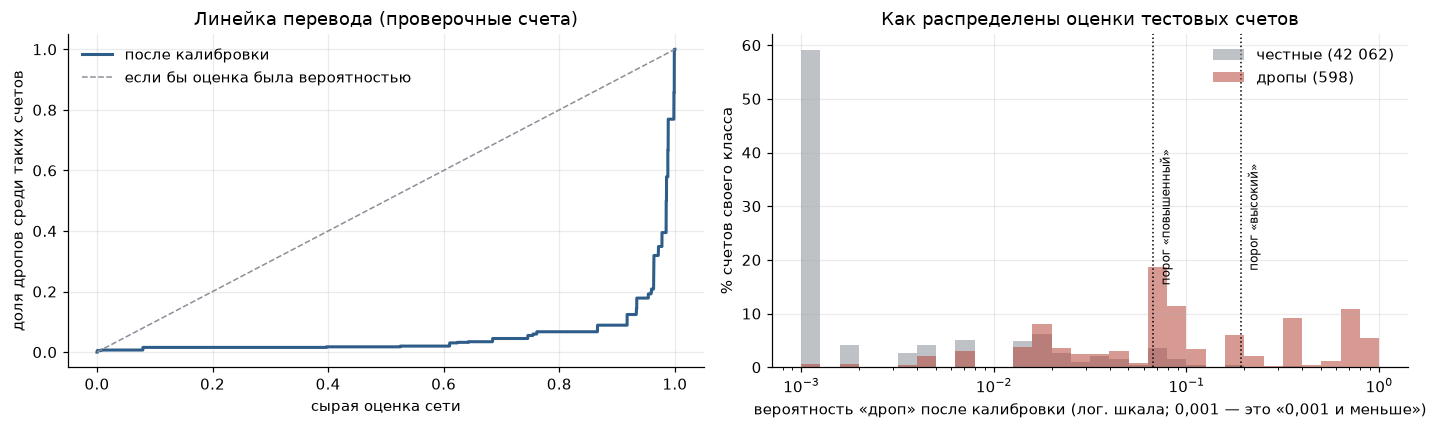

In [ ]:
# @title Калибровка и пороги
from sklearn.isotonic import IsotonicRegression
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s_sage[va], y[va])
prob_sage = iso.predict(s_sage).astype(np.float32)

pp_, rr_, tt_ = precision_recall_curve(y[va], prob_sage[va])
f1_ = (2 * pp_ * rr_ / np.maximum(pp_ + rr_, 1e-9))[:-1]
THR_HIGH = float(tt_[int(np.argmax(f1_))])
THR_ELEV = float(min(np.quantile(prob_sage[va & (y == 0)], 0.95), THR_HIGH * 0.999))
print(f"Порог «высокий риск»:   {THR_HIGH:.3f}")
print(f"Порог «повышенный риск»: {THR_ELEV:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
o = np.argsort(s_sage[va])
ax[0].plot(s_sage[va][o], iso.predict(s_sage[va][o]), color=BLUE, lw=2, label="после калибровки")
ax[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="если бы оценка была вероятностью")
ax[0].set_xlabel("сырая оценка сети"); ax[0].set_ylabel("доля дропов среди таких счетов")
ax[0].set_title("Линейка перевода (проверочные счета)"); ax[0].legend(frameon=False, loc="upper left")

bins = np.concatenate([[0], np.logspace(-3, 0, 31)])
for cls, colr, lab in [(0, GREY, "честные"), (1, RED, "дропы")]:
    v = prob_sage[te & (y == cls)]
    ax[1].hist(np.clip(v, 1e-3, 1), bins=bins[1:], weights=np.full(len(v), 100 / len(v)),
               color=colr, alpha=0.55, label=f"{lab} ({len(v):,})".replace(",", " "))
for t_, lab in [(THR_ELEV, "порог «повышенный»"), (THR_HIGH, "порог «высокий»")]:
    ax[1].axvline(t_, color="black", ls=":", lw=1)
    ax[1].text(t_ * 1.08, ax[1].get_ylim()[1] * 0.45, lab, fontsize=8, rotation=90, va="center")
ax[1].set_xscale("log"); ax[1].set_xlabel("вероятность «дроп» после калибровки (лог. шкала; 0,001 — это «0,001 и меньше»)")
ax[1].set_ylabel("% счетов своего класса"); ax[1].set_title("Как распределены оценки тестовых счетов")
ax[1].legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

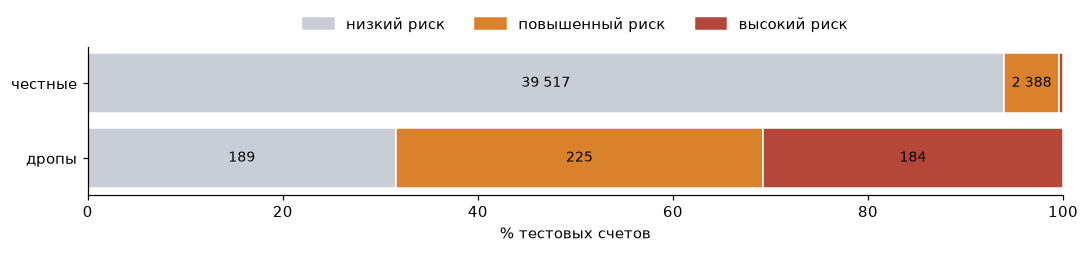

,честные,дропы
низкий риск,39517,189
повышенный риск,2388,225
высокий риск,157,184


In [ ]:
# @title Решения на тестовых счетах
zone = np.where(prob_sage >= THR_HIGH, 2, np.where(prob_sage >= THR_ELEV, 1, 0))
ZONES = ["низкий риск", "повышенный риск", "высокий риск"]
ZCOL = ["#c9ced6", ORANGE, RED]
tab = pd.DataFrame({cls: [int(((zone == z) & te & (y == k)).sum()) for z in range(3)]
                    for cls, k in [("честные", 0), ("дропы", 1)]}, index=ZONES)

fig, ax = plt.subplots(figsize=(10, 2.4))
for row, cls in enumerate(["дропы", "честные"]):
    left, total = 0, tab[cls].sum()
    for z in range(3):
        share = tab.loc[ZONES[z], cls] / total * 100
        ax.barh(row, share, left=left, color=ZCOL[z], edgecolor="white")
        if share > 4:
            ax.text(left + share / 2, row, f"{tab.loc[ZONES[z], cls]:,}".replace(",", " "), ha="center", va="center", fontsize=9)
        left += share
ax.set_yticks([0, 1]); ax.set_yticklabels(["дропы", "честные"]); ax.set_xlim(0, 100); ax.set_xlabel("% тестовых счетов")
ax.legend(handles=[Patch(color=c_, label=z_) for c_, z_ in zip(ZCOL, ZONES)], ncol=3, frameon=False,
          loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.grid(False); plt.tight_layout(); plt.show()
tab

**Как читать.** Верхняя полоса — все дропы теста, нижняя — все честные получатели теста. Красная часть верхней полосы — пойманные дропы, красная часть нижней — ложные тревоги. Порог «высокий риск» здесь выбран по откалиброванной вероятности, а в разделе «Результат на тесте» — по сырой оценке. Поэтому числа пойманных дропов и ложных тревог могут немного отличаться.

#### Что даёт граф: закрываем сети глаза

Берём **ту же обученную сеть** и вместо среднего по отправителям и/или получателям подаём нули. Сеть не переобучается — мы смотрим, насколько её решения держатся на соседях. Если без соседей качество падает почти до уровня регрессии, значит, сеть действительно пользуется графом.

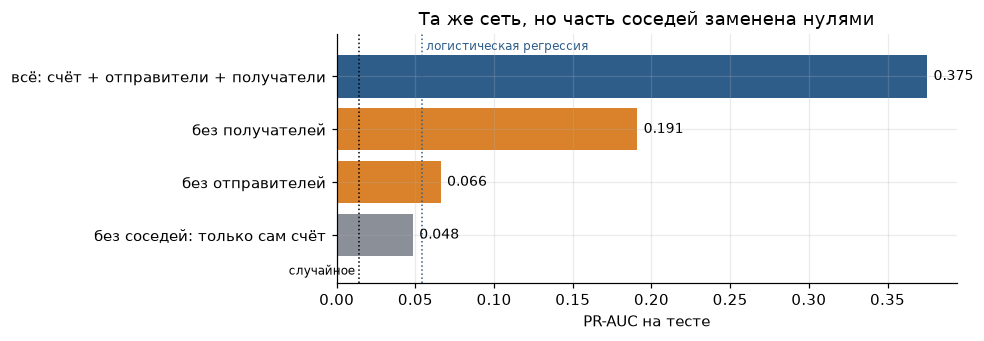

In [ ]:
# @title Четыре варианта на одних и тех же тестовых счетах
ABL = {}
for title, ui, uo in [("всё: счёт + отправители + получатели", True, True),
                      ("без получателей", True, False),
                      ("без отправителей", False, True),
                      ("без соседей: только сам счёт", False, False)]:
    sc = sage_forward(ui, uo)
    ABL[title] = average_precision_score(y[te], sc[te])
abl = pd.Series(ABL)

fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.barh(abl.index[::-1], abl.values[::-1], color=[GREY, ORANGE, ORANGE, BLUE])
for b_ in bars:
    ax.text(b_.get_width() + 0.004, b_.get_y() + b_.get_height() / 2, f"{b_.get_width():.3f}", va="center", fontsize=9)
ax.axvline(RESULTS["Логистическая регрессия"]["PR-AUC"], color=BLUE, ls=":", lw=1)
ax.text(RESULTS["Логистическая регрессия"]["PR-AUC"], 3.5, " логистическая регрессия", color=BLUE, fontsize=8)
ax.axvline(y[te].mean(), color="black", ls=":", lw=1)
ax.text(y[te].mean(), -0.75, "случайное ", color="black", fontsize=8, ha="right")
ax.set_ylim(-0.9, 3.8)
ax.set_xlabel("PR-AUC на тесте"); ax.set_title("Та же сеть, но часть соседей заменена нулями")
plt.tight_layout(); plt.show()

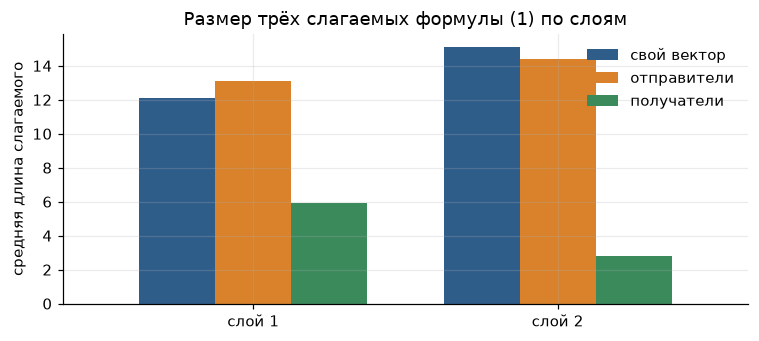

,свой вектор,отправители,получатели
слой 1,12.09,13.11,5.95
слой 2,15.11,14.38,2.78


In [ ]:
# @title Чей вклад больше: свой, отправителей или получателей
# Для каждого слоя считаем средний размер (длину вектора) трёх слагаемых формулы (1) по тестовым счетам.
te_idx = torch.tensor(np.where(te)[0]).to(X_t.device)
contrib = []
with torch.no_grad():
    h = X_t
    for k, layer in enumerate(model.layers, 1):
        parts = {"свой вектор": layer.self_lin(h), "отправители": layer.in_lin(a_in @ h), "получатели": layer.out_lin(a_out @ h)}
        contrib.append({name: float(p_[te_idx].norm(dim=1).mean()) for name, p_ in parts.items()})
        h = torch.relu(sum(parts.values()))
contrib = pd.DataFrame(contrib, index=[f"слой {k}" for k in range(1, len(contrib) + 1)])

ax = contrib.plot.bar(color=[BLUE, ORANGE, GREEN], figsize=(7, 3.2), rot=0, width=0.75)
ax.set_ylabel("средняя длина слагаемого"); ax.set_title("Размер трёх слагаемых формулы (1) по слоям")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
contrib.round(2)

#### На какие признаки опирается сеть

Тот же приём, что у бустинга: перемешиваем один из 17 признаков **у всех счетов графа** и смотрим, насколько падает PR-AUC на тесте. Перемешанный признак портит не только сам счёт, но и то, что сеть узнаёт о нём от соседей.

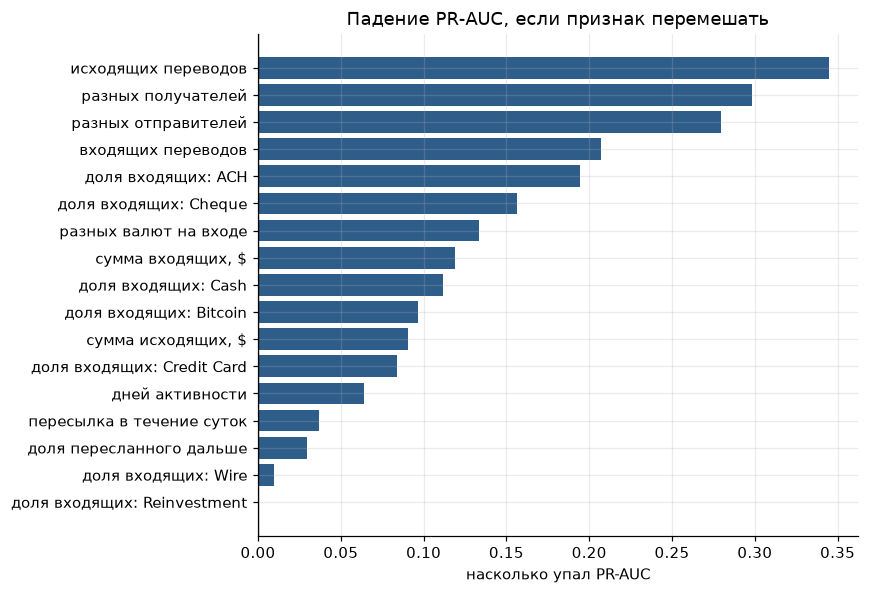

In [ ]:
# @title Важность 17 признаков для GraphSAGE (около минуты)
rng_sage = np.random.default_rng(0)
base_sage = average_precision_score(y[te], s_sage[te])
sage_imp = {}
for j_, name in enumerate(FEATURE_NAMES):
    xp_ = x.copy()
    xp_[:, j_] = xp_[rng_sage.permutation(N), j_]
    sc = sage_forward(x_input=torch.tensor(xp_).to(X_t.device))
    sage_imp[name] = base_sage - average_precision_score(y[te], sc[te])
sage_imp = pd.Series(sage_imp).sort_values()

plt.figure(figsize=(8, 5.5))
plt.barh(sage_imp.index, sage_imp.values, color=BLUE)
plt.axvline(0, color="black", lw=0.8)
plt.title("Падение PR-AUC, если признак перемешать"); plt.xlabel("насколько упал PR-AUC")
plt.tight_layout(); plt.show()

#### Карта, которую выучила нейросеть

После двух слоёв у каждого счёта 64 числа — его описание «глазами сети». Голова сети по этим 64 числам ставит оценку. Метод **t-SNE** укладывает 64-мерные точки на плоскость так, чтобы похожие для сети счета оказались рядом.

Слева для сравнения та же процедура для **17 исходных признаков** — так видно, что именно добавила сеть. Показаны тестовые счета: все дропы и 3 500 случайных честных получателей (как на карте в лаборатории).

[https://www.jmlr.org/papers/v9/vandermaaten08a.html] — van der Maaten L., Hinton G. «Visualizing Data using t-SNE», 2008.

[https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html]

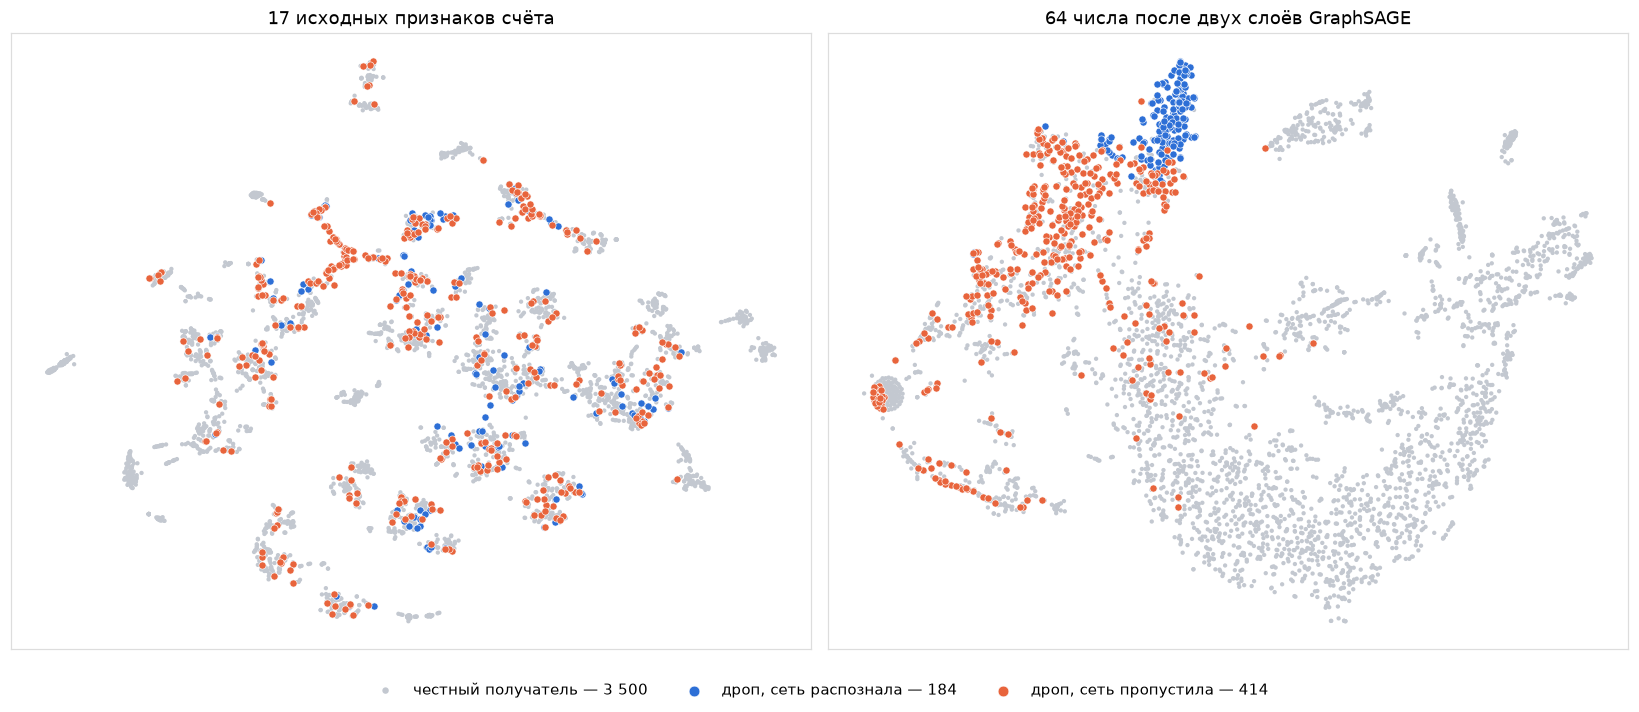

In [ ]:
# @title Описания счетов и две карты t-SNE (1–2 минуты)
from sklearn.manifold import TSNE
_, EMB = sage_forward(return_h=True)                 # 64 числа для каждого счёта

r_map = np.random.default_rng(1)
te_ids = np.where(te)[0]
map_pos = te_ids[y[te_ids] == 1]
map_neg = r_map.choice(te_ids[y[te_ids] == 0], size=min(3500, int((y[te_ids] == 0).sum())), replace=False)
map_idx = np.concatenate([map_neg, map_pos])         # дропы рисуются последними — поверх
xy_raw = TSNE(n_components=2, perplexity=35, init="pca", random_state=1).fit_transform(x[map_idx])
xy_emb = TSNE(n_components=2, perplexity=35, init="pca", random_state=1).fit_transform(EMB[map_idx])

caught = prob_sage[map_idx] >= THR_HIGH
groups = [("честный получатель", (y[map_idx] == 0), "#c3c8d0", 8),
          ("дроп, сеть распознала", (y[map_idx] == 1) & caught, "#2d6fd6", 22),
          ("дроп, сеть пропустила", (y[map_idx] == 1) & ~caught, "#e8643c", 22)]
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, xy, title in [(axs[0], xy_raw, "17 исходных признаков счёта"),
                      (axs[1], xy_emb, "64 числа после двух слоёв GraphSAGE")]:
    for lab, m_, colr, s_ in groups:
        ax.scatter(xy[m_, 0], xy[m_, 1], s=s_, color=colr, edgecolor="white" if s_ > 10 else "none",
                   linewidth=0.4, label=f"{lab} — {int(m_.sum()):_}".replace("_", " "))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#dddddd")
handles, labels = axs[1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=3, markerscale=1.5)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**Как читать карту.** Оси у t-SNE ничего не значат — важно только, кто рядом с кем. Цвет «распознала / пропустила» — по порогу «высокий риск».

- **Слева** (исходные признаки) дропы рассыпаны по множеству мелких групп вперемешку с честными счетами: по одному счёту их не отделить.
- **Справа** (после сети) распознанные дропы (синие) собраны в одну плотную группу. Рядом с ней — большая часть пропущенных (оранжевые): сеть считает их похожими на дропов, но их оценка не дотянула до порога. Остальные пропущенные лежат среди честных — для сети они от честных почти не отличаются.

Расположение групп меняется от запуска к запуску (зависит от `SEED` и случайности t-SNE), но общая картина остаётся.

#### Какие схемы отмывания находит сеть

Для каждой схемы из `HI-Small_Patterns.txt` берём счета, которые получали в ней деньги, оставляем только **тестовые** и смотрим, какую долю сеть отнесла к «высокому риску».

Не все «грязные» переводы датасета расписаны по схемам в этом файле (сколько именно — напечатано выше), поэтому это срез, а не полная картина.

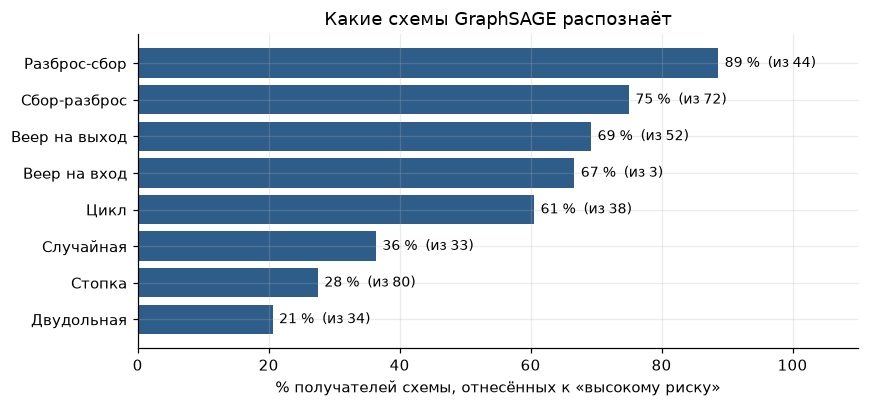

In [ ]:
# @title Доля найденных получателей по схемам (тестовые счета)
rows_ = []
for code_, name in SCHEMES.items():
    rec = {key_index[t[1]] for a in attempts if a["type"] == code_ for t in a["txns"] if t[1] in key_index}
    rec = np.array(sorted(rec), dtype=np.int64)
    rec_te = rec[te[rec]] if len(rec) else rec
    if len(rec_te):
        rows_.append({"схема": name, "получателей в тесте": len(rec_te), "найдено, %": (prob_sage[rec_te] >= THR_HIGH).mean() * 100})
schemes_tab = pd.DataFrame(rows_).sort_values("найдено, %")

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(schemes_tab["схема"], schemes_tab["найдено, %"], color=BLUE)
for b_, n_ in zip(bars, schemes_tab["получателей в тесте"]):
    ax.text(b_.get_width() + 1, b_.get_y() + b_.get_height() / 2, f"{b_.get_width():.0f} %  (из {n_})", va="center", fontsize=9)
ax.set_xlim(0, 110); ax.set_xlabel("% получателей схемы, отнесённых к «высокому риску»")
ax.set_title("Какие схемы GraphSAGE распознаёт")
plt.tight_layout(); plt.show()

**Осторожно с выводами:** в некоторых схемах тестовых получателей всего несколько, и один счёт меняет процент на десятки пунктов — смотрите на число в скобках.

#### Разбор настоящего счёта

Берём дроп из тестовой выборки (при обучении сеть его не видела), которого сеть отнесла к «высокому риску», с небольшим числом соседей — чтобы всё поместилось на рисунок. Смотрим по шагам: кто его окружает, что сеть думает о соседях, что будет, если закрыть ей глаза, и что о нём думают две другие модели.

In [ ]:
# @title Выбираем счёт
cand = np.where(te & (y == 1) & (prob_sage >= THR_HIGH) & (indeg_all >= 3) & (indeg_all <= 7)
                & (outdeg_all >= 1) & (outdeg_all <= 3))[0]
if not len(cand):
    cand = np.where(te & (y == 1) & (prob_sage >= THR_HIGH))[0]
CASE = int(cand[np.argmax(prob_sage[cand])])
CASE_COLS = ego_columns(CASE)
print(f"Счёт {keys[CASE]}: отправителей {indeg_all[CASE]}, получателей {outdeg_all[CASE]}")
print(f"Вероятность «дроп» по мнению сети: {prob_sage[CASE]:.2f}   (по разметке датасета это действительно дроп)")

case_tab = pd.DataFrame({"сам счёт": raw[CASE],
                         "среднее по отправителям": raw[senders_of(CASE)].mean(0),
                         "среднее по получателям": raw[receivers_of(CASE)].mean(0),
                         "типичный честный получатель": np.median(raw[recipients & (y == 0)], 0)},
                        index=FEATURE_NAMES)
case_tab.round(2)

Счёт 0012979:80593EE80: отправителей 3, получателей 1
Вероятность «дроп» по мнению сети: 0.86   (по разметке датасета это действительно дроп)


,сам счёт,среднее по отправителям,среднее по получателям,типичный честный получатель
входящих переводов,17.000000,3.367000e+01,12.00,16.000000
исходящих переводов,1.000000,5.667000e+01,6.00,1.000000
"сумма входящих, $",53208.519531,2.480870e+05,4967675.00,26530.029297
"сумма исходящих, $",14246.440430,8.073160e+07,1354319.50,2217.760010
разных отправителей,3.000000,3.000000e+00,8.00,2.000000
разных получателей,1.000000,6.000000e+00,2.00,1.000000
доля пересланного дальше,0.270000,3.460000e+00,0.27,0.040000
пересылка в течение суток,0.000000,1.300000e-01,0.50,0.000000
дней активности,13.220000,1.084000e+01,13.66,8.650000
разных валют на входе,1.000000,1.000000e+00,1.00,1.000000


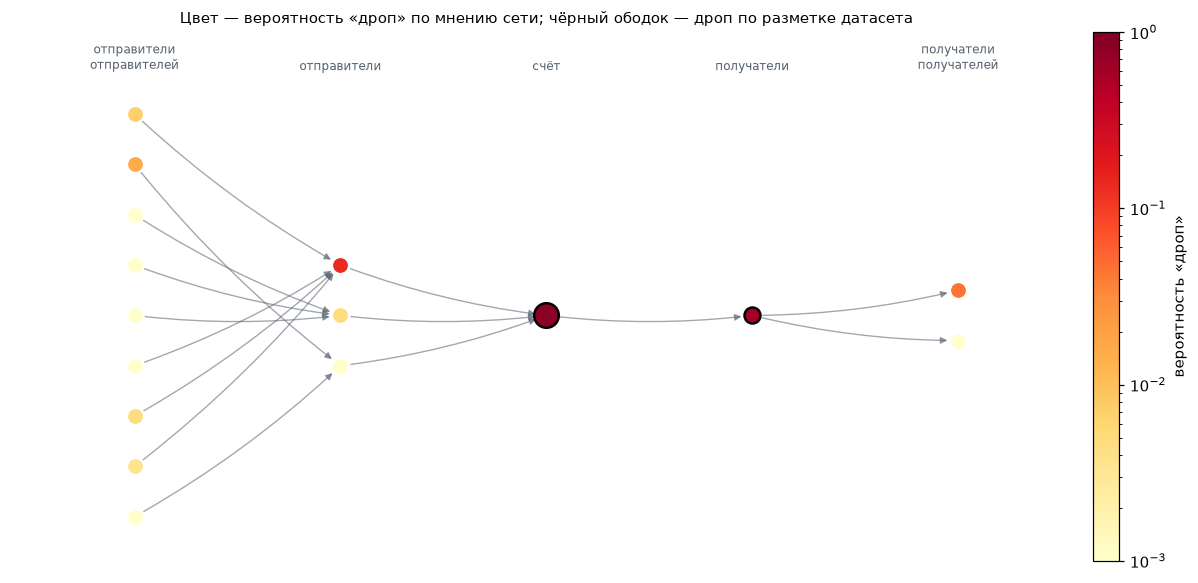

In [ ]:
# @title Окрестность глазами сети
from matplotlib import cm, colors as mcolors
norm_ = mcolors.LogNorm(vmin=1e-3, vmax=1)
cmap_ = plt.get_cmap("YlOrRd")
fig, ax = plt.subplots(figsize=(11, 5.4))
draw_ego(ax, CASE_COLS, lambda u: cmap_(norm_(max(float(prob_sage[u]), 1e-3))),
         ring={u for c_ in CASE_COLS.values() for u in c_.tolist() if y[u] == 1},
         title="Цвет — вероятность «дроп» по мнению сети; чёрный ободок — дроп по разметке датасета")
cb = fig.colorbar(cm.ScalarMappable(norm=norm_, cmap=cmap_), ax=ax, fraction=0.025, pad=0.01)
cb.set_label("вероятность «дроп»")
plt.tight_layout(); plt.show()

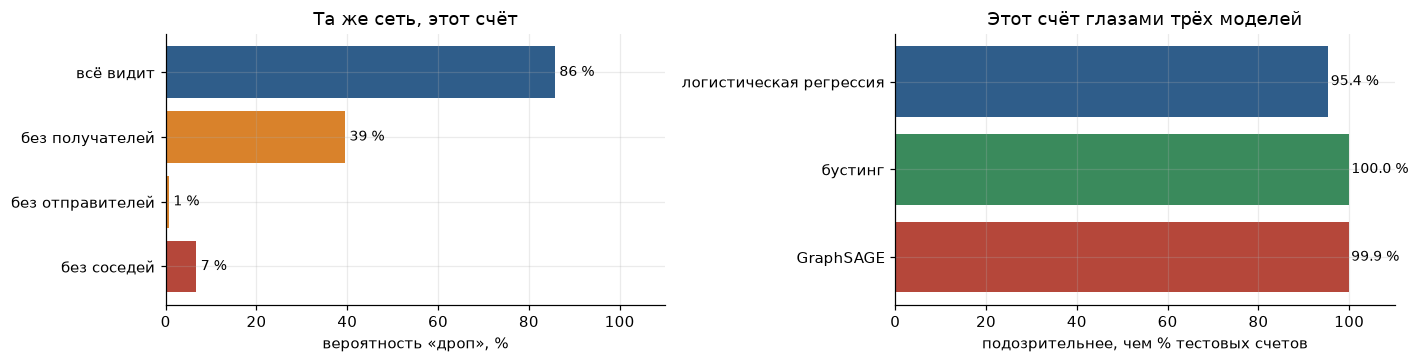

In [ ]:
# @title Что, если закрыть сети глаза — для этого счёта
what_if = {}
for title, ui, uo in [("всё видит", True, True), ("без получателей", True, False),
                      ("без отправителей", False, True), ("без соседей", False, False)]:
    what_if[title] = float(iso.predict([sage_forward(ui, uo)[CASE]])[0])
what_if = pd.Series(what_if)

# Тот же счёт глазами трёх моделей. Оценки разных моделей несравнимы напрямую,
# поэтому показываем место в рейтинге: «подозрительнее, чем X % тестовых счетов».
def pct_rank(score):
    return (score[te] < score[CASE]).mean() * 100
ranks = pd.Series({"логистическая регрессия": pct_rank(s_logreg), "бустинг": pct_rank(s_boost), "GraphSAGE": pct_rank(s_sage)})

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
b1 = ax[0].barh(what_if.index[::-1], what_if.values[::-1] * 100, color=[BLUE, ORANGE, ORANGE, RED][::-1])
for b_ in b1:
    ax[0].text(b_.get_width() + 1, b_.get_y() + b_.get_height() / 2, f"{b_.get_width():.0f} %", va="center", fontsize=9)
ax[0].set_xlim(0, 110); ax[0].set_xlabel("вероятность «дроп», %"); ax[0].set_title("Та же сеть, этот счёт")
b2 = ax[1].barh(ranks.index[::-1], ranks.values[::-1], color=[RED, GREEN, BLUE])
for b_ in b2:
    ax[1].text(b_.get_width() + 0.5, b_.get_y() + b_.get_height() / 2, f"{b_.get_width():.1f} %", va="center", fontsize=9)
ax[1].set_xlim(0, 110); ax[1].set_xlabel("подозрительнее, чем % тестовых счетов")
ax[1].set_title("Этот счёт глазами трёх моделей")
plt.tight_layout(); plt.show()

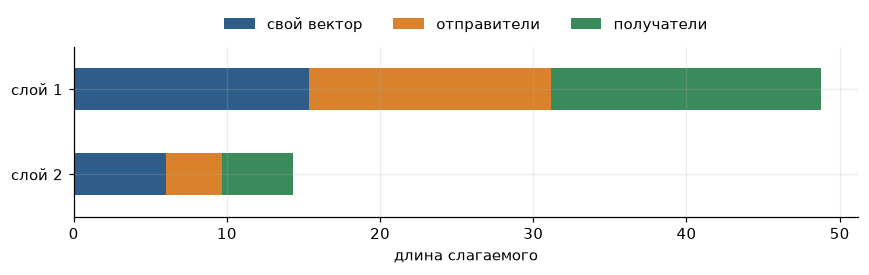

,свой вектор,отправители,получатели,активных чисел из 64
слой 1,15.35,15.78,17.63,10
слой 2,6.04,3.62,4.63,10


In [ ]:
# @title Как менялось описание счёта по слоям
case_parts = []
with torch.no_grad():
    h = X_t
    for k, layer in enumerate(model.layers, 1):
        parts = {"свой вектор": layer.self_lin(h), "отправители": layer.in_lin(a_in @ h), "получатели": layer.out_lin(a_out @ h)}
        h = torch.relu(sum(parts.values()))
        case_parts.append({**{n_: float(p_[CASE].norm()) for n_, p_ in parts.items()},
                           "активных чисел из 64": int((h[CASE] > 0).sum())})
case_parts = pd.DataFrame(case_parts, index=[f"слой {k}" for k in range(1, len(case_parts) + 1)])

ax = case_parts[["свой вектор", "отправители", "получатели"]].plot.barh(stacked=True, color=[BLUE, ORANGE, GREEN], figsize=(8, 2.6))
ax.invert_yaxis(); ax.set_xlabel("длина слагаемого"); ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()
case_parts.round(2)

**Итог разбора.** На этом счёте видно то же, что в «закрываем глаза» для всего теста. В нашем прогоне (`SEED = 42`) сеть дала ему 86 %, без соседей — 7 %, а без одних только отправителей — 1 %. Решение держится в первую очередь на том, **кто присылал** деньги, а не на признаках самого счёта.

Рисунки выше посчитаны для конкретного счёта. После переобучения с другими параметрами числа (и даже выбранный счёт) могут быть другими.

---
## Сравнение моделей

Все модели проверены на одних и тех же тестовых счетах.

#### Таблица

In [ ]:
cols = ["PR-AUC", "ROC-AUC", "полнота при 1% ложных", "точность топ-100", "поймано дропов", "пропущено дропов", "ложных тревог"]
table = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in RESULTS.items()}).T
table.style.format({c: "{:.3f}" for c in cols[:4]}).background_gradient(subset=["PR-AUC"], cmap="Blues")

,PR-AUC,ROC-AUC,полнота при 1% ложных,точность топ-100,поймано дропов,пропущено дропов,ложных тревог
Правило,0.033,0.679,0.059,0.100,52.000000,546.000000,753.000000
Логистическая регрессия,0.054,0.799,0.059,0.090,121.000000,477.000000,1338.000000
Бустинг,0.338,0.935,0.318,0.960,159.000000,439.000000,186.000000
GraphSAGE,0.375,0.933,0.385,0.890,185.000000,413.000000,162.000000


Кривые «точность - полнота» всех моделей

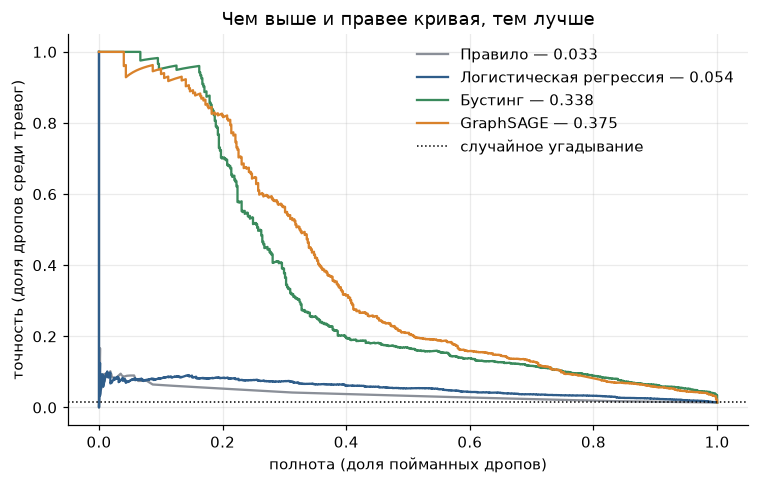

In [ ]:
palette = [GREY, BLUE, GREEN, ORANGE, RED, "#6b5b95"]
plt.figure(figsize=(7, 4.5))
for (name, v), col in zip(RESULTS.items(), palette):
    p, r, _ = precision_recall_curve(y[te], v["score"][te])
    plt.plot(r, p, color=col, label=f"{name} — {v['PR-AUC']:.3f}")
plt.axhline(y[te].mean(), color="black", ls=":", lw=1, label="случайное угадывание")
plt.xlabel("полнота (доля пойманных дропов)"); plt.ylabel("точность (доля дропов среди тревог)")
plt.legend(frameon=False); plt.title("Чем выше и правее кривая, тем лучше")
plt.tight_layout(); plt.show()

### Результат

Модели, которые видят только сам счёт (правило, логистическая регрессия), почти не отличают дропа от честного получателя: PR-AUC 0,033 и 0,054 при случайном уровне 0,014. Как только модель видит окружение счёта, качество растёт в разы: бустинг со средними по соседям – 0,338, GraphSAGE – 0,375. Риск получателя определяется прежде всего его связями – это аргумент за графовый подход.

Бустинг и GraphSAGE близки, и это честный результат: бустинг получил уже готовые средние по соседям, то есть «один слой GraphSAGE», посчитанный вручную. На своих порогах у GraphSAGE найдено дропов – 184, ложных тревог – 157; у бустинга – 159 и 186; зато среди 100 самых подозрительных счетов у бустинга дропов чуть больше (96 против 89). Кроме цифр, у GraphSAGE два принципиальных плюса: она видит на два шага по графу, а признаки соседей не нужно придумывать и пересчитывать вручную.

# Интересные статьи, найденные в процессе разбора:
*  Учебник по машинному обучению Яндекса, глава «Графовые нейронные сети»: передача сообщений, агрегация соседей, GraphSAGE. https://contest.yandex.ru/tracks/ml/deep-learning-architectures/graph-neural-networks#graphsage
*   Краткое введение в графовые нейронные сети. https://distill.pub/2021/gnn-intro/
*   Первоисточник. Hamilton W., Ying R., Leskovec J. «Inductive Representation Learning on Large Graphs». https://arxiv.org/abs/1706.02216
*   GraphSAGE: Индуктивное обучение представлений на больших графах (с кодом с GitHub) https://snap.stanford.edu/graphsage/
*   Исследование с выбранным датасетом. Altman E. и др. «Realistic Synthetic Financial Transactions for Anti-Money Laundering Models», 2023. https://arxiv.org/abs/2306.16424
*   Учебник по машинному обучению Яндекса, главы «Линейные модели для классификации» и «Градиентный бустинг». https://contest.yandex.ru/tracks/ml/
*   GraphSAGE против мошенничества. Tare M. и др. «Representation Learning on Large Non-Bipartite Transaction Networks using GraphSAGE», 2025. https://arxiv.org/abs/2509.12255